# Nhiệm vụ 2 và 3 Chuẩn bị dữ liệu và phân tích bất động sản

Notebook tái lập cho chủ đề 14, nhóm 4. Dùng **King County** và **Ames** nguyên bản; báo cáo mô tả lịch sử giao dịch, làm sạch theo quy tắc minh bạch, so sánh hai nhóm giá và kiểm tra giả thuyết quan hệ.

**Cách chạy:** từ thư mục dự án, cài `requirements.txt`, chạy `python scripts/prepare_data.py`, rồi Run All notebook. Chạy từ thư mục `notebooks` cũng được. ETL sử dụng bản raw đã lưu và chỉ tải lại khi raw chưa tồn tại. Tất cả số liệu dưới đây được tính bằng mã, không gán thủ công.

Không xây mô hình dự báo hoặc chọn 20 ứng viên đầu tư trong nhiệm vụ này. `undervalued` trong EDA chỉ là **nhãn nhóm giá thấp theo trung vị**, chưa phải bằng chứng bị định giá thấp so với thị trường.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image, Code, Markdown
ROOT = Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
assert (ROOT/"scripts/prepare_data.py").exists(), "Mở notebook từ thư mục dự án hoặc notebooks"
print("Thư mục dự án:", ROOT)


Thư mục dự án: <thu_muc_du_an>


## Nhiệm vụ 2 ETL bốn bước

1. **Extract:** tải dữ liệu và tài liệu mô tả; lưu raw, URL, SHA-256 và thời điểm tải.
2. **Transform:** chuẩn hóa schema, kiểu dữ liệu và giao dịch; giữ giao dịch bán lặp của King County, loại trùng hoàn toàn; sửa hoặc cách ly giá trị không hợp lệ có dấu vết.
3. **Transform và tạo biến:** xử lý thiếu theo ngữ nghĩa, tạo `price_per_sqft = price / sqft_living`, `house_age = sale_year - year_built` với cờ các tuổi âm cần xử lý; Haversine dùng bán kính Trái Đất 6.371,0088 km và mốc Seattle do nhóm chọn. Biến từ giá là biến mô tả, không được dùng làm đầu vào dự báo giá.
4. **Load và kiểm tra:** lưu hai CSV sạch, từ điển dữ liệu, audit; assert số dòng, miền giá trị và công thức.

Phạm vi diện tích khác nhau: King County tính diện tích trong nhà có tầng hầm, Ames dùng diện tích ở trên mặt đất. Vì vậy không so trực tiếp price_per_sqft giữa hai thị trường.

Ames nguyên bản không có `lat`, `long`, `zipcode`. Khoảng cách của Ames được giữ thiếu có lý do, không nội suy tọa độ; dùng `neighborhood` để phân nhóm địa lý. Điểm ngoài khoảng 1,5 IQR được gắn cờ; các giá trị cực đoan hợp lệ vẫn được giữ. Mã ETL đầy đủ được hiển thị dưới đây để kiểm tra quy tắc chi tiết.

In [2]:
etl_source = (ROOT/"scripts/prepare_data.py").read_text(encoding="utf8")
display(Code(etl_source, language="python"))
etl_process = subprocess.run([sys.executable, str(ROOT/"scripts/prepare_data.py")], check=True, capture_output=True, text=True)
print(etl_process.stdout)


"""Nhiệm vụ 2: ETL có lưu nguồn, dấu vết và kiểm tra dữ liệu nhà ở.

Chạy từ thư mục gốc: python scripts/prepare_data.py
Thêm --refresh để tải lại các nguồn; mặc định dùng raw đã lưu và kiểm SHA256.
"""
from pathlib import Path
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
import argparse
import hashlib
import json
import re
import urllib.request

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
SOURCES = {
    "king_county": {
        "file": "kc_house_data.csv",
        "url": "https://raw.githubusercontent.com/jmatth11/King-County-House-Data-Set/master/kc_house_data.csv",
        "origin": "https://www.kaggle.com/datasets/harlfoxem/housesalesprediction",
        "note": "Bản sao CSV công khai của dữ liệu Kaggle; không phải tải trực tiếp từ Kaggle.",
    },
    "ames": {
        "file": "AmesHousing.txt",
        "url": "https://jse.amstat.org/v19n3/decock/AmesHousing.txt",
        "origin": "https://jse.amstat.org/v19n3/decock.pdf",
        "note": "Dữ liệu gốc kèm bài báo De Cock 2011.",
    },
    "ames_documentation": {
        "file": "Ames_DataDocumentation.txt",
        "url": "https://jse.amstat.org/v19n3/decock/DataDocumentation.txt",
        "origin": "https://jse.amstat.org/v19n3/decock/DataDocumentation.txt",
        "note": "Từ điển gốc gồm mã danh mục và ý nghĩa NA.",
    },
}

AMES_DESCRIPTIONS = {
    "order": "Số thứ tự quan sát trong nguồn", "pid": "Mã thửa đất",
    "ms_subclass": "Mã loại hình nhà ở", "ms_zoning": "Phân khu sử dụng đất",
    "lot_frontage": "Chiều dài mặt tiền giáp đường", "lot_area": "Diện tích thửa đất",
    "street": "Loại đường tiếp cận", "alley": "Loại đường hẻm tiếp cận",
    "lot_shape": "Hình dạng thửa đất", "land_contour": "Địa hình thửa đất",
    "utilities": "Hệ thống tiện ích công cộng", "lot_config": "Vị trí và cấu hình lô đất",
    "land_slope": "Độ dốc đất", "neighborhood": "Mã khu dân cư Ames",
    "condition_1": "Điều kiện lân cận thứ nhất", "condition_2": "Điều kiện lân cận thứ hai",
    "bldg_type": "Loại công trình nhà ở", "house_style": "Kiểu bố trí tầng của nhà",
    "overall_qual": "Chất lượng vật liệu và hoàn thiện tổng thể từ 1 đến 10",
    "overall_cond": "Tình trạng tổng thể từ 1 đến 10", "year_built": "Năm xây dựng",
    "year_remod_add": "Năm cải tạo hoặc mở rộng", "roof_style": "Kiểu mái",
    "roof_matl": "Vật liệu mái", "exterior_1st": "Vật liệu tường ngoài chính",
    "exterior_2nd": "Vật liệu tường ngoài bổ sung", "mas_vnr_type": "Loại lớp ốp xây ngoài",
    "mas_vnr_area": "Diện tích lớp ốp xây ngoài", "exter_qual": "Chất lượng hoàn thiện bên ngoài",
    "exter_cond": "Tình trạng bên ngoài", "foundation": "Loại móng",
    "bsmt_qual": "Chất lượng chiều cao tầng hầm", "bsmt_cond": "Tình trạng tầng hầm",
    "bsmt_exposure": "Mức tiếp xúc bên ngoài của tầng hầm", "bsmtfin_type_1": "Loại hoàn thiện tầng hầm phần 1",
    "bsmtfin_sf_1": "Diện tích hoàn thiện tầng hầm phần 1", "bsmtfin_type_2": "Loại hoàn thiện tầng hầm phần 2",
    "bsmtfin_sf_2": "Diện tích hoàn thiện tầng hầm phần 2", "bsmt_unf_sf": "Diện tích tầng hầm chưa hoàn thiện",
    "total_bsmt_sf": "Tổng diện tích tầng hầm", "heating": "Loại hệ thống sưởi",
    "heating_qc": "Chất lượng hệ thống sưởi", "central_air": "Có điều hòa trung tâm",
    "electrical": "Loại hệ thống điện", "1st_flr_sf": "Diện tích tầng một",
    "2nd_flr_sf": "Diện tích tầng hai", "low_qual_fin_sf": "Diện tích hoàn thiện chất lượng thấp",
    "gr_liv_area": "Diện tích sinh hoạt trên mặt đất", "bsmt_full_bath": "Số phòng tắm đầy đủ tầng hầm",
    "bsmt_half_bath": "Số phòng vệ sinh nửa tầng hầm", "full_bath": "Số phòng tắm đầy đủ trên mặt đất",
    "half_bath": "Số phòng vệ sinh nửa trên mặt đất", "bedroom_abvgr": "Số phòng ngủ trên mặt đất",
    "kitchen_abvgr": "Số bếp trên mặt đất", "kitchen_qual": "Chất lượng bếp",
    "totrms_abvgrd": "Tổng số phòng trên mặt đất không kể phòng tắm", "functional": "Mức độ đáp ứng công năng",
    "fireplaces": "Số lò sưởi", "firep

{
  "king_county": {
    "raw_rows": 21613,
    "raw_columns": 21,
    "clean_rows": 21612,
    "clean_columns": 34,
    "quarantined_rows": 1,
    "exact_duplicates_removed": 0,
    "unique_properties": 21435,
    "repeat_transaction_rows_beyond_first": 177,
    "raw_date_min": "2014-05-02",
    "raw_date_max": "2015-05-27",
    "age_capped_zero": 12,
    "zero_room_flag": 16,
    "price_iqr_outliers": 1146,
    "area_iqr_outliers": 572,
    "iqr_limits": {
      "price": {
        "q1": 321837.5,
        "q3": 645000.0,
        "low": -162906.25,
        "high": 1129743.75
      },
      "sqft_living": {
        "q1": 1426.5,
        "q3": 2550.0,
        "low": -258.75,
        "high": 4235.25
      }
    },
    "center": {
      "label": "Điểm đại diện trung tâm Seattle do nhóm quy ước",
      "lat": 47.6062,
      "long": -122.3321
    },
    "distance_formula": "Haversine; R=6371.0088 km; đường chim bay, không phải thời gian đi lại"
  },
  "ames": {
    "raw_rows": 2930,
    "raw

In [3]:
etl_summary = json.loads((ROOT/"metadata/etl_summary.json").read_text(encoding="utf8"))
print(json.dumps(etl_summary, ensure_ascii=False, indent=2))
for filename in ["missingness_before_after.csv", "outlier_audit.csv", "imputation_audit.csv"]:
    print("\n", filename)
    display(pd.read_csv(ROOT/"metadata"/filename).head(20))
print("Từ điển dữ liệu đầy đủ:")
display(pd.read_csv(ROOT/"dictionaries/data_dictionary.csv"))


{
  "king_county": {
    "raw_rows": 21613,
    "raw_columns": 21,
    "clean_rows": 21612,
    "clean_columns": 34,
    "quarantined_rows": 1,
    "exact_duplicates_removed": 0,
    "unique_properties": 21435,
    "repeat_transaction_rows_beyond_first": 177,
    "raw_date_min": "2014-05-02",
    "raw_date_max": "2015-05-27",
    "age_capped_zero": 12,
    "zero_room_flag": 16,
    "price_iqr_outliers": 1146,
    "area_iqr_outliers": 572,
    "iqr_limits": {
      "price": {
        "q1": 321837.5,
        "q3": 645000.0,
        "low": -162906.25,
        "high": 1129743.75
      },
      "sqft_living": {
        "q1": 1426.5,
        "q3": 2550.0,
        "low": -258.75,
        "high": 4235.25
      }
    },
    "center": {
      "label": "Điểm đại diện trung tâm Seattle do nhóm quy ước",
      "lat": 47.6062,
      "long": -122.3321
    },
    "distance_formula": "Haversine; R=6371.0088 km; đường chim bay, không phải thời gian đi lại"
  },
  "ames": {
    "raw_rows": 2930,
    "raw

,dataset,raw_column,clean_column,missing_before,missing_after,rows_before,rows_after
0,king_county,id,id,0,0,21613,21612
1,king_county,date,date,0,0,21613,21612
2,king_county,price,price,0,0,21613,21612
3,king_county,bedrooms,bedrooms,0,0,21613,21612
4,king_county,bathrooms,bathrooms,0,0,21613,21612
5,king_county,sqft_living,sqft_living,0,0,21613,21612
6,king_county,sqft_lot,sqft_lot,0,0,21613,21612
7,king_county,floors,floors,0,0,21613,21612
8,king_county,waterfront,waterfront,0,0,21613,21612
9,king_county,view,view,0,0,21613,21612



 outlier_audit.csv


,dataset,source_row_id,property_id,price,sqft_living,raw_house_age,flags,action
0,king_county,6,7237550310,1225000.0,5420,13,price_iqr_outlier;area_iqr_outlier,retained_with_flags
1,king_county,22,2524049179,2000000.0,3050,46,price_iqr_outlier,retained_with_flags
2,king_county,50,822039084,1350000.0,2753,62,price_iqr_outlier,retained_with_flags
3,king_county,70,1802000060,1325000.0,3200,49,price_iqr_outlier,retained_with_flags
4,king_county,71,1525059190,1040000.0,4770,41,area_iqr_outlier,retained_with_flags
5,king_county,116,3626039325,740500.0,4380,114,area_iqr_outlier,retained_with_flags
6,king_county,126,4389200955,1450000.0,2750,101,price_iqr_outlier,retained_with_flags
7,king_county,154,7855801670,2250000.0,5180,9,price_iqr_outlier;area_iqr_outlier,retained_with_flags
8,king_county,217,46100204,1505000.0,3300,58,price_iqr_outlier,retained_with_flags
9,king_county,240,5152100060,472000.0,4410,49,area_iqr_outlier,retained_with_flags



 imputation_audit.csv


,dataset,source_row_id,column,before,after,rule
0,ames,1,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
1,ames,2,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
2,ames,3,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
3,ames,4,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
4,ames,5,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
5,ames,6,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
6,ames,7,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
7,ames,8,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
8,ames,9,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích
9,ames,10,alley,<MISSING>,No_feature,NA theo từ điển gốc nghĩa là không có tiện ích


Từ điển dữ liệu đầy đủ:


,dataset,column,raw_column,dtype_clean,unit,description_vi,role,target_leakage,missing_policy,missing_after,n_unique,documentation
0,king_county,source_row_id,derived,int64,số dòng gốc bắt đầu từ 1,Số dòng dữ liệu gốc bắt đầu từ 1 không kể tiêu...,identifier; không dùng làm biến liên tục,0,Biến suy ra từ các trường sạch; không có missi...,0,21612,https://www.kaggle.com/datasets/harlfoxem/hous...
1,king_county,id,id,string,mã bất động sản dạng chuỗi,Mã bất động sản; có thể xuất hiện nhiều giao dịch,identifier; không dùng làm biến liên tục,0,Không thiếu ở raw; giữ nguyên giá trị. Chuyển ...,0,21435,https://www.kaggle.com/datasets/harlfoxem/hous...
2,king_county,date,date,str,ngày ISO YYYY-MM-DD,Ngày bán định dạng ISO 8601,candidate_feature; xét thời điểm sẵn có và fit...,0,Không thiếu ở raw; giữ nguyên giá trị. Chỉ chu...,0,372,https://www.kaggle.com/datasets/harlfoxem/hous...
3,king_county,price,price,float64,USD danh nghĩa tại thời điểm bán,Giá bán thực tế,target hoặc target_alias,1,Không thiếu ở raw; giữ nguyên giá trị. Chuyển ...,0,4028,https://www.kaggle.com/datasets/harlfoxem/hous...
4,king_county,bedrooms,bedrooms,int64,phòng ngủ,Số phòng ngủ,candidate_feature; xét thời điểm sẵn có và fit...,0,Không thiếu ở raw; giữ nguyên giá trị. Chuyển ...,0,12,https://www.kaggle.com/datasets/harlfoxem/hous...
...,...,...,...,...,...,...,...,...,...,...,...,...
152,ames,distance_to_center_km,derived,float64,km,Khoảng cách đường chim bay Haversine đến điểm ...,candidate_feature; xét thời điểm sẵn có và fit...,0,NA có chủ đích cho toàn bộ hàng vì nguồn không...,2930,0,https://jse.amstat.org/v19n3/decock/DataDocume...
153,ames,distance_available,derived,int8,0 hoặc 1,Cờ 1 nếu có tọa độ thực để tính khoảng cách; 0...,quality_flag; xem mục đích sử dụng,0,Biến suy ra từ các trường sạch; không có missi...,0,1,https://jse.amstat.org/v19n3/decock/DataDocume...
154,ames,price_iqr_outlier,derived,int8,0 hoặc 1,Cờ giá nằm ngoài Q1 trừ 1.5IQR hoặc Q3 cộng 1....,"EDA_only; chứa giá mục tiêu, loại khỏi X dự báo",1,Biến suy ra từ các trường sạch; không có missi...,0,2,https://jse.amstat.org/v19n3/decock/DataDocume...
155,ames,area_iqr_outlier,derived,int8,0 hoặc 1,Cờ diện tích sinh hoạt nằm ngoài ngưỡng 1.5IQR...,quality_flag; xem mục đích sử dụng,0,Biến suy ra từ các trường sạch; không có missi...,0,2,https://jse.amstat.org/v19n3/decock/DataDocume...


## Nhiệm vụ 3 Thiết kế EDA và kiểm định

- Phân tích mô tả dùng **tất cả giao dịch sạch**. Giá và phân phối log được xem riêng cho mỗi thị trường; không gộp hai thành phố hoặc quy đổi thời gian theo giả định.
- Nhãn chính: `price < 0.8 × median(price)` trong từng bộ dữ liệu sạch, dấu `<` nghiêm ngặt. Kiểm tra độ nhạy với ngưỡng 10%, 20%, 30% và trung vị địa phương (`zipcode` hoặc `neighborhood`).
- Suy luận King County dùng **giao dịch sớm nhất mỗi tài sản** sau làm sạch để giảm phụ thuộc từ bán lặp. Ngưỡng nhãn vẫn giữ theo toàn mẫu sạch. Ames mỗi PID một quan sát. Dữ liệu còn có thể phụ thuộc không gian.
- **Welch t-test hai phía:** H0: trung bình thuộc tính hai nhóm bằng nhau. H1: khác nhau. Báo chênh lệch `nhóm thấp − còn lại`, CI95%, t, bậc tự do Welch, p thô, p Holm và Hedges g. Không kiểm định giá hoặc price_per_sqft vì cách lập nhóm đã dùng giá.
- **Giả thuyết chiều Spearman:** giá tăng theo diện tích và chất lượng; giảm theo tuổi và khoảng cách. Kiểm định một phía theo chiều kỳ vọng đã nêu; điều chỉnh Holm riêng mỗi họ kiểm định và mỗi dataset. Hệ số ngược chiều được báo trung thực. Biến thứ bậc chất lượng cần đọc cùng tương quan hạng.
- CI95% cho từng chênh lệch, không phải khoảng đồng thời đã hiệu chỉnh. `p < .05` không tự nói mức độ ảnh hưởng lớn, nên cần đọc effect size. Mọi quan hệ ở đây là quan sát, chưa mang nghĩa nhân quả.

Mã thực hiện đầy đủ nằm trong các cell tiếp theo và đồng nhất với `scripts/analyze.py`.

In [4]:
"""EDA và chẩn đoán tái lập cho nhiệm vụ 3; chạy từ bất kỳ thư mục nào."""
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd()/'scripts').exists() else Path.cwd().parent
TABLES, FIGURES = ROOT/'outputs/tables', ROOT/'outputs/figures'
for folder in (TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.dpi':120,
                     'savefig.dpi':180,'axes.spines.top':False,'axes.spines.right':False})
COLORS = {'low':'#D55E00','rest':'#0072B2'}
LABELS = {'price':'Giá bán (USD)','sqft_living':'Diện tích ở (sqft)',
          'house_age':'Tuổi nhà (năm)','sqft_lot':'Diện tích đất (sqft)',
          'lot_area':'Diện tích đất (sqft)','grade':'Hạng chất lượng',
          'overall_qual':'Chất lượng tổng thể','bathrooms':'Số phòng tắm',
          'bedrooms':'Số phòng ngủ','bedroom_abvgr':'Phòng ngủ trên mặt đất',
          'distance_to_center_km':'Khoảng cách đến mốc trung tâm (km)',
          'bathrooms_total':'Phòng tắm trên mặt đất (quy đổi)'}

def holm(pvalues):
    """Holm step-down, kiểm soát family-wise error; giữ NaN khi không kiểm định được."""
    p = np.asarray(pvalues, dtype=float)
    result = np.full(len(p), np.nan)
    valid = np.flatnonzero(np.isfinite(p)); order = valid[np.argsort(p[valid])]
    result[order] = np.minimum(1, np.maximum.accumulate((len(order)-np.arange(len(order)))*p[order]))
    return result

def truth(s):
    if s.dtype == bool: return s.fillna(False)
    return s.astype(str).str.lower().isin(['true','1','1.0'])

def independent_sample(df, dataset):
    """Đơn vị suy luận King là tài sản: giữ giao dịch sớm nhất, không chọn theo giá."""
    if dataset == 'king_county':
        return df.sort_values(['date','source_row_id']).drop_duplicates('id',keep='first').copy()
    # De Cock giữ giao dịch mới nhất mỗi PID trước khi công bố dữ liệu Ames.
    assert not df['pid'].duplicated().any(), 'Ames PID lặp: cần xác định đơn vị độc lập'
    return df.copy()

def welch_row(df, field):
    low = pd.to_numeric(df.loc[df.undervalued_global,field],errors='coerce').dropna().to_numpy()
    rest = pd.to_numeric(df.loc[~df.undervalued_global,field],errors='coerce').dropna().to_numpy()
    n1,n0=len(low),len(rest)
    if min(n1,n0)<3: return None
    m1,m0=low.mean(),rest.mean(); v1,v0=low.var(ddof=1),rest.var(ddof=1)
    se=np.sqrt(v1/n1+v0/n0)
    if se == 0: return None
    dfree=(v1/n1+v0/n0)**2/((v1/n1)**2/(n1-1)+(v0/n0)**2/(n0-1))
    t,p=stats.ttest_ind(low,rest,equal_var=False)
    diff=m1-m0; critical=stats.t.ppf(.975,dfree)
    pooled=np.sqrt(((n1-1)*v1+(n0-1)*v0)/(n1+n0-2))
    correction=1-3/(4*(n1+n0)-9)
    return dict(variable=field,n_low=n1,n_rest=n0,mean_low=m1,mean_rest=m0,
                difference_low_minus_rest=diff,ci95_low=diff-critical*se,
                ci95_high=diff+critical*se,t=float(t),df=dfree,p_raw=float(p),
                hedges_g=correction*diff/pooled if pooled>0 else np.nan)

def savefig(name):
    plt.savefig(FIGURES/f'{name}.png',bbox_inches='tight')
    plt.savefig(FIGURES/f'{name}.svg',bbox_inches='tight')
    plt.close()

def draw_figures(df,key,title,fields,geo):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    sns.histplot(df.price/1000,bins=55,color=COLORS['rest'],ax=axes[0])
    axes[0].axvline(.8*df.price.median()/1000,color=COLORS['low'],ls='--',label='Ngưỡng 80% trung vị')
    axes[0].set(xlabel='Giá bán (nghìn USD)',ylabel='Số giao dịch',title='Thang giá gốc')
    axes[0].legend(fontsize=9)
    sns.histplot(np.log10(df.price),bins=45,color=COLORS['rest'],ax=axes[1])
    axes[1].set(xlabel='log10 giá bán (USD)',ylabel='Số giao dịch',title='Thang logarit')
    fig.suptitle(f'{title} | Phân phối giá bán',fontweight='bold'); fig.tight_layout()
    savefig(f'{key}_price_distribution')
    medians=df.groupby(geo).price.median().sort_values()
    order=list(medians.index); chunks=np.array_split(np.array(order,dtype=object),2 if len(order)>40 else 1)
    fig,axes=plt.subplots(1,len(chunks),figsize=(14 if len(chunks)>1 else 10,11),squeeze=False)
    for ax,chunk in zip(axes.flat,chunks):
        sns.boxplot(data=df,x='price',y=geo,order=list(chunk),color='#9BC9E0',showfliers=False,ax=ax)
        ax.set_xscale('log'); ax.set(xlabel='Giá bán USD (thang log)',ylabel='Mã ZIP' if geo=='zipcode' else 'Khu dân cư')
        counts=df[geo].value_counts()
        ax.set_yticks(range(len(chunk)),[f'{x} (n={counts[x]:,})' for x in chunk],fontsize=9)
        ax.grid(axis='x',alpha=.2)
    if len(chunks)>1:
        limits=(min(ax.get_xlim()[0] for ax in axes.flat),max(ax.get_xlim()[1] for ax in axes.flat))
        for ax in axes.flat:
            ax.set_xticks([100000,300000,1000000,3000000],['100k','300k','1M','3M'])
            ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
            ax.set_xlim(limits)
    else:
        limits=axes.flat[0].get_xlim()
        axes.flat[0].set_xticks([20000,50000,100000,200000,500000],['20k','50k','100k','200k','500k'])
        axes.flat[0].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        axes.flat[0].set_xlim(limits)
    fig.suptitle(f'{title} | Giá theo {"zipcode" if geo=="zipcode" else "neighborhood"}\nSắp theo trung vị; ẩn điểm ngoại lệ trên biểu đồ, vẫn giữ trong thống kê',fontweight='bold',fontsize=13)
    fig.tight_layout(rect=[0,0,1,.95]); savefig(f'{key}_geographic_boxplot')
    selected=['price']+fields
    corr=df[selected].corr(method='spearman')
    fig,ax=plt.subplots(figsize=(10,8))
    sns.heatmap(corr,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1,center=0,
                xticklabels=[LABELS.get(x,x) for x in selected],yticklabels=[LABELS.get(x,x) for x in selected],ax=ax)
    ax.set_title(f'{title} | Tương quan hạng Spearman',pad=15,fontweight='bold')
    ax.tick_params(axis='x',labelrotation=65); fig.tight_layout(); savefig(f'{key}_spearman_heatmap')
    view=['sqft_living','house_age','grade' if key=='king_county' else 'overall_qual',
          'distance_to_center_km' if key=='king_county' else 'bathrooms_total']
    fig,axes=plt.subplots(1,4,figsize=(14,4.3))
    for ax,field in zip(axes,view):
        groups=[df.loc[df.undervalued_global,field].dropna(),df.loc[~df.undervalued_global,field].dropna()]
        bp=ax.boxplot(groups,patch_artist=True,showfliers=False,widths=.55)
        for box,c in zip(bp['boxes'],COLORS.values()): box.set_facecolor(c); box.set_alpha(.65)
        ax.set_xticks([1,2],['Nhóm giá thấp','Còn lại'],rotation=20,fontsize=9)
        ax.set_title(LABELS[field],fontsize=11); ax.grid(axis='y',alpha=.15)
    fig.suptitle(f'{title} | Đặc điểm hai nhóm theo ngưỡng 80% trung vị giá',fontweight='bold')
    fig.tight_layout(); savefig(f'{key}_group_comparison')
    fig,axes=plt.subplots(1,3,figsize=(13,4.2))
    xfields=['sqft_living','house_age','distance_to_center_km' if key=='king_county' else 'overall_qual']
    for ax,field in zip(axes,xfields):
        hb=ax.hexbin(df[field],np.log10(df.price),gridsize=35,mincnt=1,cmap='Blues',bins='log')
        ax.set(xlabel=LABELS[field],ylabel='log10 giá bán (USD)')
    fig.suptitle(f'{title} | Giá và các thuộc tính',fontweight='bold')
    fig.tight_layout(); savefig(f'{key}_price_relationships')


def run_analysis():
    frames={}; summary={}; descriptives=[]; groups=[]; welch=[]; directional=[]; sensitivity=[]; geo_tables=[]
    for key,title in [('king_county','King County'),('ames','Ames')]:
        path=ROOT/f'data/processed/{key}_clean.csv'
        df=pd.read_csv(path,dtype={'id':'string','pid':'string','zipcode':'string'})
        assert df.price.gt(0).all() and df.sqft_living.gt(0).all()
        df['undervalued_global']=df.price.lt(.8*df.price.median())
        geo='zipcode' if key=='king_county' else 'neighborhood'
        localmedian=df.groupby(geo).price.transform('median')
        df['undervalued_local']=df.price.lt(.8*localmedian)
        df['local_reference_median']=localmedian
        if key=='ames':
            df['bathrooms_total']=df.full_bath+.5*df.half_bath
        fields=['sqft_living','house_age','sqft_lot','grade','bathrooms','bedrooms','distance_to_center_km'] if key=='king_county' else ['sqft_living','house_age','lot_area','overall_qual','bathrooms_total','bedroom_abvgr']
        sample=independent_sample(df,key)
        desc=df[['price','price_per_sqft']+fields].describe(percentiles=[.01,.25,.5,.75,.99]).T.reset_index(names='variable')
        desc.insert(0,'dataset',key); descriptives.append(desc)
        for field in ['price','price_per_sqft']+fields:
            for low,label in [(True,'low_price'),(False,'rest')]:
                values=df.loc[df.undervalued_global.eq(low),field].dropna()
                groups.append(dict(dataset=key,group=label,variable=field,n=len(values),mean=values.mean(),median=values.median(),sd=values.std()))
        wr=[welch_row(sample,field) for field in fields]; wr=[r for r in wr if r]
        adj=holm([r['p_raw'] for r in wr])
        for r,padj in zip(wr,adj):
            r.update(dataset=key,p_holm=padj,significant_holm=bool(padj<.05),sample='one_sale_per_property',
                     group_threshold=.8*df.price.median()); welch.append(r)
        expected={'sqft_living':'positive','house_age':'negative','grade' if key=='king_county' else 'overall_qual':'positive'}
        if key=='king_county': expected['distance_to_center_km']='negative'
        dr=[]
        for field,direction in expected.items():
            valid=sample[[field,'price']].dropna()
            # Alternative đã khai báo theo giả thuyết trước khi tính kết quả.
            alternative='greater' if direction=='positive' else 'less'
            test=stats.spearmanr(valid[field],valid.price,alternative=alternative)
            dr.append(dict(dataset=key,variable=field,expected_direction=direction,n=len(valid),rho=float(test.statistic),p_one_sided=float(test.pvalue),sample='one_sale_per_property'))
        for r,padj in zip(dr,holm([r['p_one_sided'] for r in dr])):
            same=(r['rho']>0) == (r['expected_direction']=='positive')
            r.update(p_holm=padj,conclusion='supported' if same and padj<.05 else ('opposite_observed' if not same else 'inconclusive'))
            directional.append(r)
        for discount in [.1,.2,.3]:
            g=df.price.lt((1-discount)*df.price.median()); loc=df.price.lt((1-discount)*localmedian)
            sensitivity.append(dict(dataset=key,analysis='threshold',discount=discount,reference='global',n=len(df),n_low=int(g.sum()),share_low=float(g.mean()),overlap_with_global20=int((g & df.undervalued_global).sum())))
            sensitivity.append(dict(dataset=key,analysis='threshold',discount=discount,reference=geo,n=len(df),n_low=int(loc.sum()),share_low=float(loc.mean()),overlap_with_global20=int((loc & df.undervalued_global).sum())))
        subsets={'all_transactions':df,'one_sale_per_property':sample,
                 'exclude_price_or_area_iqr':sample.loc[~(truth(sample.price_iqr_outlier)|truth(sample.area_iqr_outlier))],
                 'exclude_true_imputation':sample.loc[~truth(sample.has_true_imputation)]}
        if key=='ames':
            subsets['exclude_ames_over_4000_sqft']=sample.loc[sample.sqft_living.le(4000)]
        for name,sub in subsets.items():
            sr=[welch_row(sub,f) for f in fields]; sr=[r for r in sr if r]
            for r,padj in zip(sr,holm([r['p_raw'] for r in sr])):
                sensitivity.append(dict(dataset=key,analysis='welch_robustness',reference=name,n=len(sub),variable=r['variable'],difference_low_minus_rest=r['difference_low_minus_rest'],p_raw=r['p_raw'],p_holm=padj,n_low=r['n_low'],n_rest=r['n_rest'],hedges_g=r['hedges_g']))
        geo_tab=df.groupby(geo).agg(n=('price','size'),median_price=('price','median'),mean_price=('price','mean'),n_low_global=('undervalued_global','sum'),n_low_local=('undervalued_local','sum')).reset_index()
        geo_tab.insert(0,'dataset',key); geo_tab.rename(columns={geo:'geography'},inplace=True); geo_tables.append(geo_tab)
        df[['source_row_id','price','local_reference_median','undervalued_global','undervalued_local']].to_csv(TABLES/f'{key}_group_labels.csv',index=False)
        summary[key]=dict(name=title,n=len(df),n_independent=len(sample),median_price=float(df.price.median()),mean_price=float(df.price.mean()),min_price=float(df.price.min()),max_price=float(df.price.max()),price_skew=float(df.price.skew()),threshold_global20=float(.8*df.price.median()),n_low=int(df.undervalued_global.sum()),share_low=float(df.undervalued_global.mean()),n_low_local=int(df.undervalued_local.sum()),share_low_local=float(df.undervalued_local.mean()),n_overlap_global_local=int((df.undervalued_global & df.undervalued_local).sum()),n_geographies=int(df[geo].nunique()),sale_year_min=int(pd.to_datetime(df.date).dt.year.min()) if key=='king_county' else int(df.yr_sold.min()),sale_year_max=int(pd.to_datetime(df.date).dt.year.max()) if key=='king_county' else int(df.yr_sold.max()),n_resales_removed_inference=int(len(df)-len(sample)),fields=fields)
        draw_figures(df,key,title,fields,geo)
        frames[key]=df
    pd.concat(descriptives).to_csv(TABLES/'summary_statistics.csv',index=False)
    pd.DataFrame(groups).to_csv(TABLES/'group_summary.csv',index=False)
    pd.DataFrame(welch).to_csv(TABLES/'welch_tests.csv',index=False)
    pd.DataFrame(directional).to_csv(TABLES/'directional_tests.csv',index=False)
    pd.DataFrame(sensitivity).to_csv(TABLES/'sensitivity.csv',index=False)
    pd.concat(geo_tables).to_csv(TABLES/'geographic_summary.csv',index=False)
    result={'definition':'price < 0.8 * median(price) trong từng bộ dữ liệu sạch; strict <',
            'interpretation':'Nhãn low-price proxy, không chứng minh nhà bị định giá thấp so với giá trị thị trường.',
            'inference':'King County dùng giao dịch sớm nhất mỗi id; Ames mỗi PID một quan sát. Ngưỡng nhóm giữ theo toàn bộ dữ liệu sạch.',
            'alpha':.05,'multiple_testing':'Holm điều chỉnh riêng từng dataset và từng họ Welch hoặc Spearman; CI95% Welch riêng từng biến, không đồng thời.',
            'datasets':summary,'welch':welch,'directional':directional}
    (TABLES/'analysis_summary.json').write_text(json.dumps(result,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf8')
    lines=['NHIỆM VỤ 3  PHÂN TÍCH MÔ TẢ VÀ CHẨN ĐOÁN','',result['definition'],result['interpretation'],result['inference'],result['multiple_testing'],'']
    for key,s in summary.items():
        lines += [f"{s['name']}: n={s['n']:,}; suy luận n={s['n_independent']:,}; trung vị {s['median_price']:,.0f} USD; ngưỡng {s['threshold_global20']:,.0f} USD; nhóm thấp {s['n_low']:,} ({s['share_low']:.2%}); nhóm thấp theo địa phương {s['n_low_local']:,} ({s['share_low_local']:.2%})."]
        for r in welch:
            if r['dataset']==key:
                lines.append(f"Welch {r['variable']}: mean thấp={r['mean_low']:.3f}; còn lại={r['mean_rest']:.3f}; chênh lệch={r['difference_low_minus_rest']:.3f}; CI95% [{r['ci95_low']:.3f},{r['ci95_high']:.3f}]; p Holm={r['p_holm']:.4g}; Hedges g={r['hedges_g']:.3f}.")
        for r in directional:
            if r['dataset']==key: lines.append(f"Spearman {r['variable']} kỳ vọng {r['expected_direction']}: rho={r['rho']:.4f}; p Holm một phía={r['p_holm']:.4g}; kết luận={r['conclusion']}.")
    lines += ['', 'Giới hạn: t-test coi chất lượng thứ bậc như số để so trung bình; cần đọc kèm tương quan hạng. Dữ liệu quan sát lịch sử, chưa điều chỉnh đầy đủ vị trí/thời gian/chất lượng nên không diễn dịch nhân quả. Phụ thuộc không gian có thể còn lại dù bỏ bán lặp. P-value có thể rất nhỏ do cỡ mẫu lớn, phải đọc CI và effect size. Ames nguyên bản không có tọa độ hoặc zipcode; không tính khoảng cách và dùng neighborhood thay thế phân nhóm địa lý. Các giao dịch giá cao hợp lệ được giữ; loại điểm IQR chỉ là sensitivity. Median nhóm tính toàn mẫu phục vụ EDA; khi mô hình hóa phải fit ngưỡng/imputation trên train để tránh leakage. Không dùng price_per_sqft hoặc nhãn undervalued làm predictor giá.']
    (ROOT/'docs/eda_interpretation.txt').write_text('\n'.join(lines),encoding='utf8')
    assert len(welch)==13 and len(directional)==7
    assert all(0<=r['p_holm']<=1 for r in welch+directional)
    assert all(r['ci95_low']<=r['difference_low_minus_rest']<=r['ci95_high'] for r in welch)
    assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
    print(json.dumps(summary,ensure_ascii=False,indent=2))
    return result




In [5]:
results = run_analysis()
display(pd.DataFrame(results["datasets"]).T)


/var/folders/ms/yqt7c73d40xdz8383n8b6rtw0000gp/T/ipykernel_5547/794477106.py:182: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  geo_tab.insert(0,'dataset',key); geo_tab.rename(columns={geo:'geography'},inplace=True); geo_tables.append(geo_tab)


/var/folders/ms/yqt7c73d40xdz8383n8b6rtw0000gp/T/ipykernel_5547/794477106.py:182: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  geo_tab.insert(0,'dataset',key); geo_tab.rename(columns={geo:'geography'},inplace=True); geo_tables.append(geo_tab)


{
  "king_county": {
    "name": "King County",
    "n": 21612,
    "n_independent": 21435,
    "median_price": 450000.0,
    "mean_price": 540083.5187858597,
    "min_price": 75000.0,
    "max_price": 7700000.0,
    "price_skew": 4.024033595653387,
    "threshold_global20": 360000.0,
    "n_low": 7130,
    "share_low": 0.329909309642791,
    "n_low_local": 4834,
    "share_low_local": 0.22367203405515454,
    "n_overlap_global_local": 2964,
    "n_geographies": 70,
    "sale_year_min": 2014,
    "sale_year_max": 2015,
    "n_resales_removed_inference": 177,
    "fields": [
      "sqft_living",
      "house_age",
      "sqft_lot",
      "grade",
      "bathrooms",
      "bedrooms",
      "distance_to_center_km"
    ]
  },
  "ames": {
    "name": "Ames",
    "n": 2930,
    "n_independent": 2930,
    "median_price": 160000.0,
    "mean_price": 180796.0600682594,
    "min_price": 12789.0,
    "max_price": 755000.0,
    "price_skew": 1.7435000757376475,
    "threshold_global20": 128000.0,


,name,n,n_independent,median_price,mean_price,min_price,max_price,price_skew,threshold_global20,n_low,share_low,n_low_local,share_low_local,n_overlap_global_local,n_geographies,sale_year_min,sale_year_max,n_resales_removed_inference,fields
king_county,King County,21612,21435,450000.0,540083.518786,75000.0,7700000.0,4.024034,360000.0,7130,0.329909,4834,0.223672,2964,70,2014,2015,177,"[sqft_living, house_age, sqft_lot, grade, bath..."
ames,Ames,2930,2930,160000.0,180796.060068,12789.0,755000.0,1.7435,128000.0,682,0.232765,497,0.169625,258,28,2006,2010,0,"[sqft_living, house_age, lot_area, overall_qua..."


## Phân phối giá và khác biệt địa lý

Biểu đồ hộp dùng thang log để đọc được toàn bộ dải giá. Không hiển thị điểm ngoại lệ trên boxplot nhằm giảm chồng lấp, nhưng các điểm vẫn có trong thống kê và kiểm định chính. King County hiển thị tất cả zipcode; Ames hiển thị tất cả neighborhood, kèm số quan sát từng nhóm.

,dataset,variable,count,mean,std,min,1%,25%,50%,75%,99%,max
0,king_county,price,21612.0,540083.518786,367135.061269,75000.000000,153500.330000,321837.500000,450000.000000,645000.000000,1.964450e+06,7.700000e+06
1,king_county,price_per_sqft,21612.0,264.150537,110.059737,87.588235,105.457008,182.287533,244.626805,318.321203,6.321967e+02,8.101389e+02
2,king_county,sqft_living,21612.0,2079.921016,918.456818,290.000000,720.000000,1426.500000,1910.000000,2550.000000,4.978900e+03,1.354000e+04
3,king_county,house_age,21612.0,43.317277,29.374902,0.000000,0.000000,18.000000,40.000000,63.000000,1.100000e+02,1.150000e+02
4,king_county,sqft_lot,21612.0,15107.388951,41421.423497,520.000000,1013.110000,5040.000000,7619.000000,10688.250000,2.130080e+05,1.651359e+06
5,king_county,grade,21612.0,7.656904,1.175477,1.000000,5.000000,7.000000,7.000000,8.000000,1.100000e+01,1.300000e+01
6,king_county,bathrooms,21612.0,2.114774,0.770177,0.000000,1.000000,1.750000,2.250000,2.500000,4.250000e+00,8.000000e+00
7,king_county,bedrooms,21612.0,3.369471,0.907982,0.000000,2.000000,3.000000,3.000000,4.000000,6.000000e+00,1.100000e+01
8,king_county,distance_to_center_km,21612.0,18.458912,10.641906,0.983120,2.521893,9.783646,16.509968,25.266306,4.931002e+01,7.709390e+01
9,ames,price,2930.0,180796.060068,79886.692357,12789.000000,61756.070000,129500.000000,160000.000000,213500.000000,4.566664e+05,7.550000e+05


,dataset,geography,n,median_price,mean_price,n_low_global,n_low_local
0,king_county,98001,362,260000.0,2.808047e+05,305,75
1,king_county,98002,199,235000.0,2.342840e+05,196,33
2,king_county,98003,280,267475.0,2.941113e+05,236,43
3,king_county,98004,317,1150000.0,1.355927e+06,0,105
4,king_county,98005,168,765475.0,8.101649e+05,0,33
...,...,...,...,...,...,...,...
93,ames,SawyerW,125,180000.0,1.840702e+05,12,23
94,ames,Somerst,182,225500.0,2.297073e+05,0,43
95,ames,StoneBr,51,319000.0,3.242292e+05,0,19
96,ames,Timber,72,232106.5,2.465995e+05,0,18


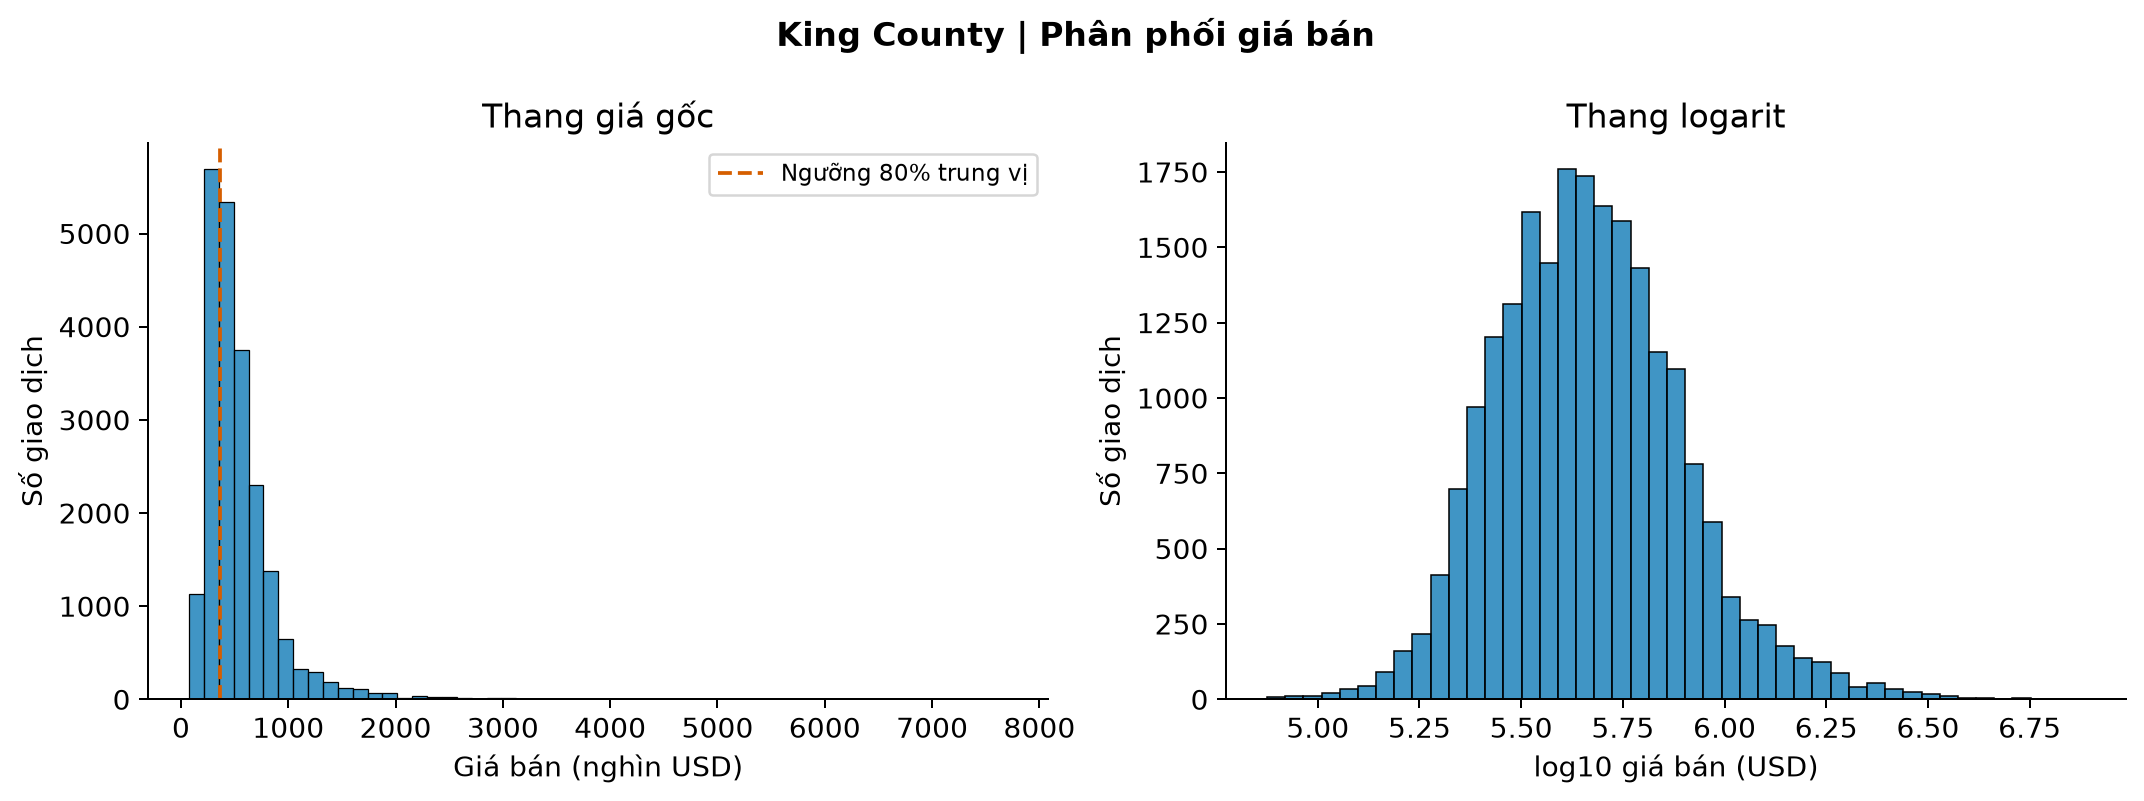

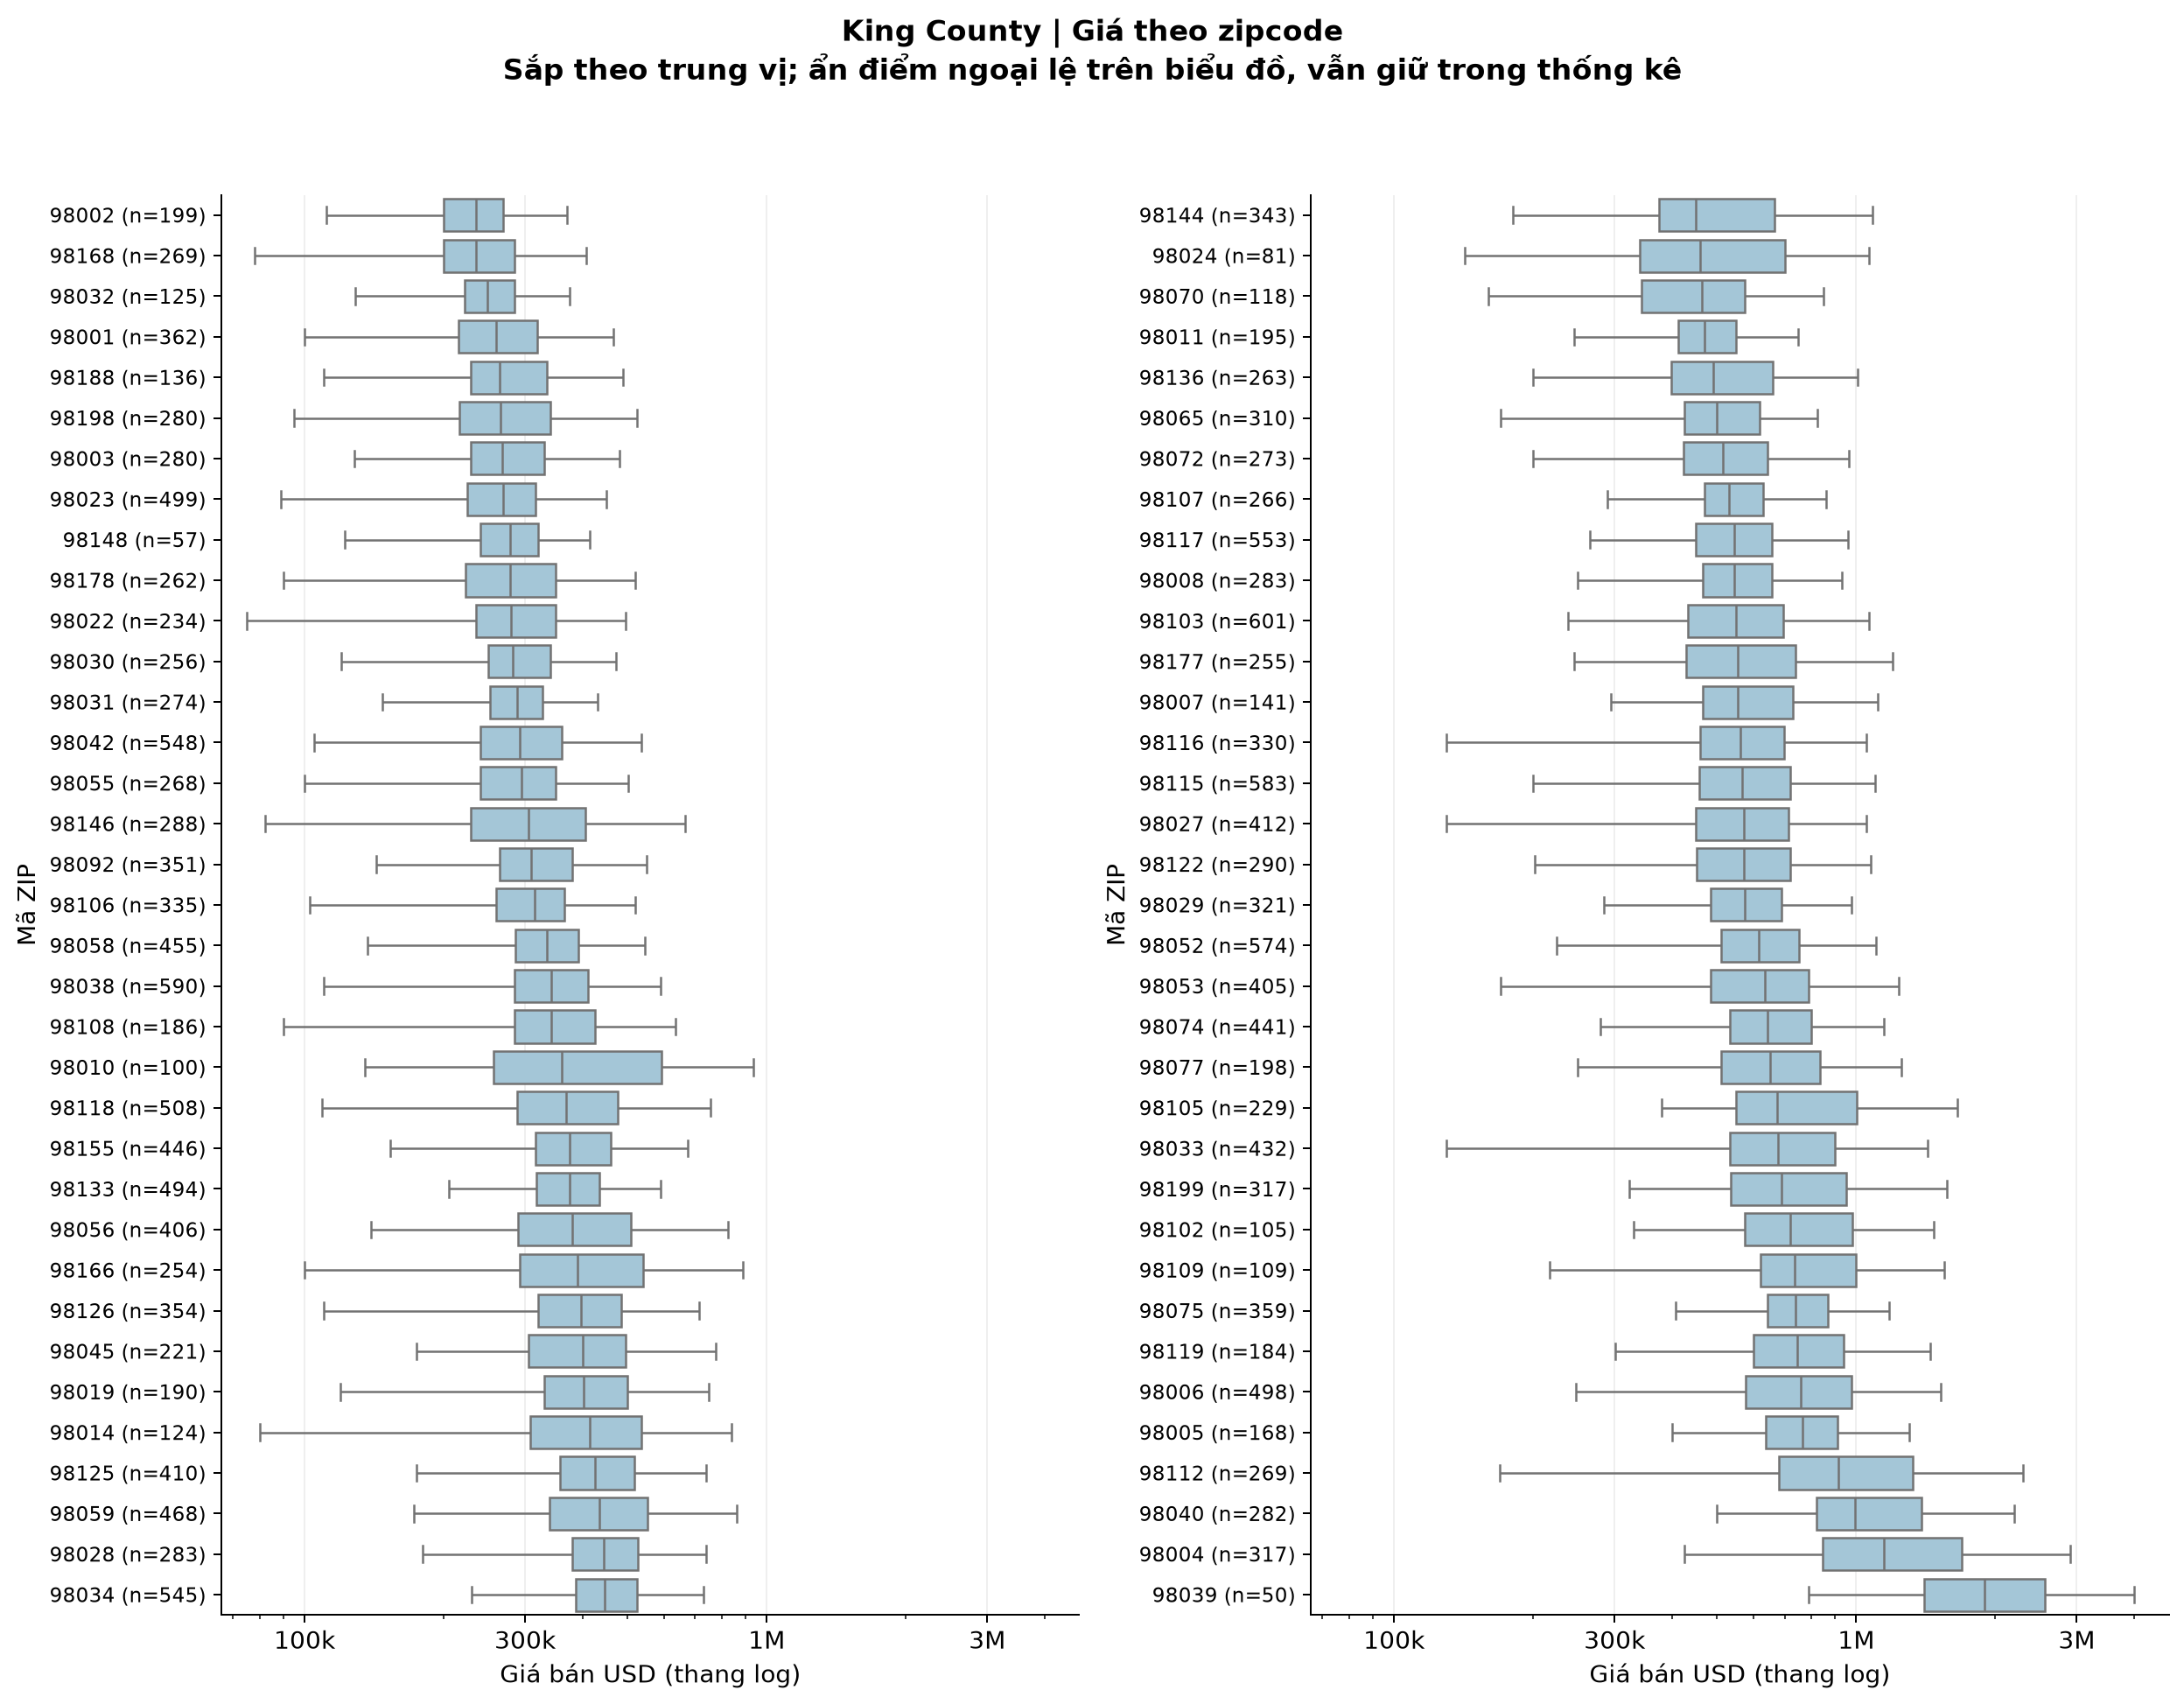

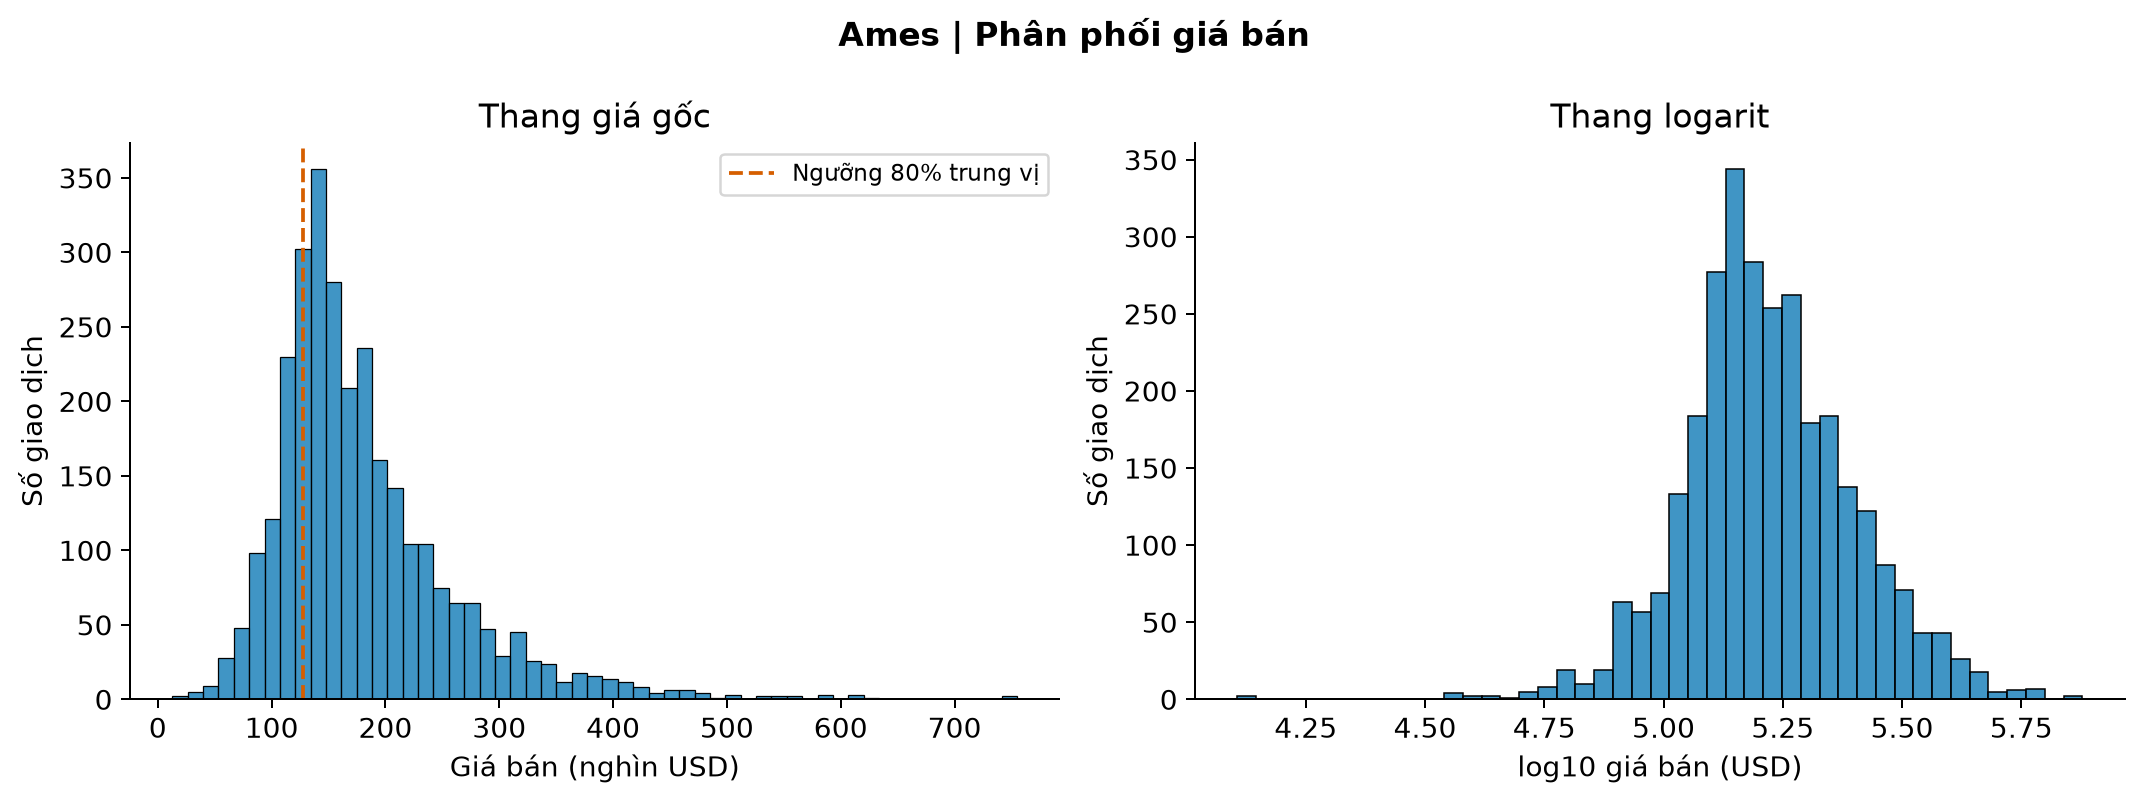

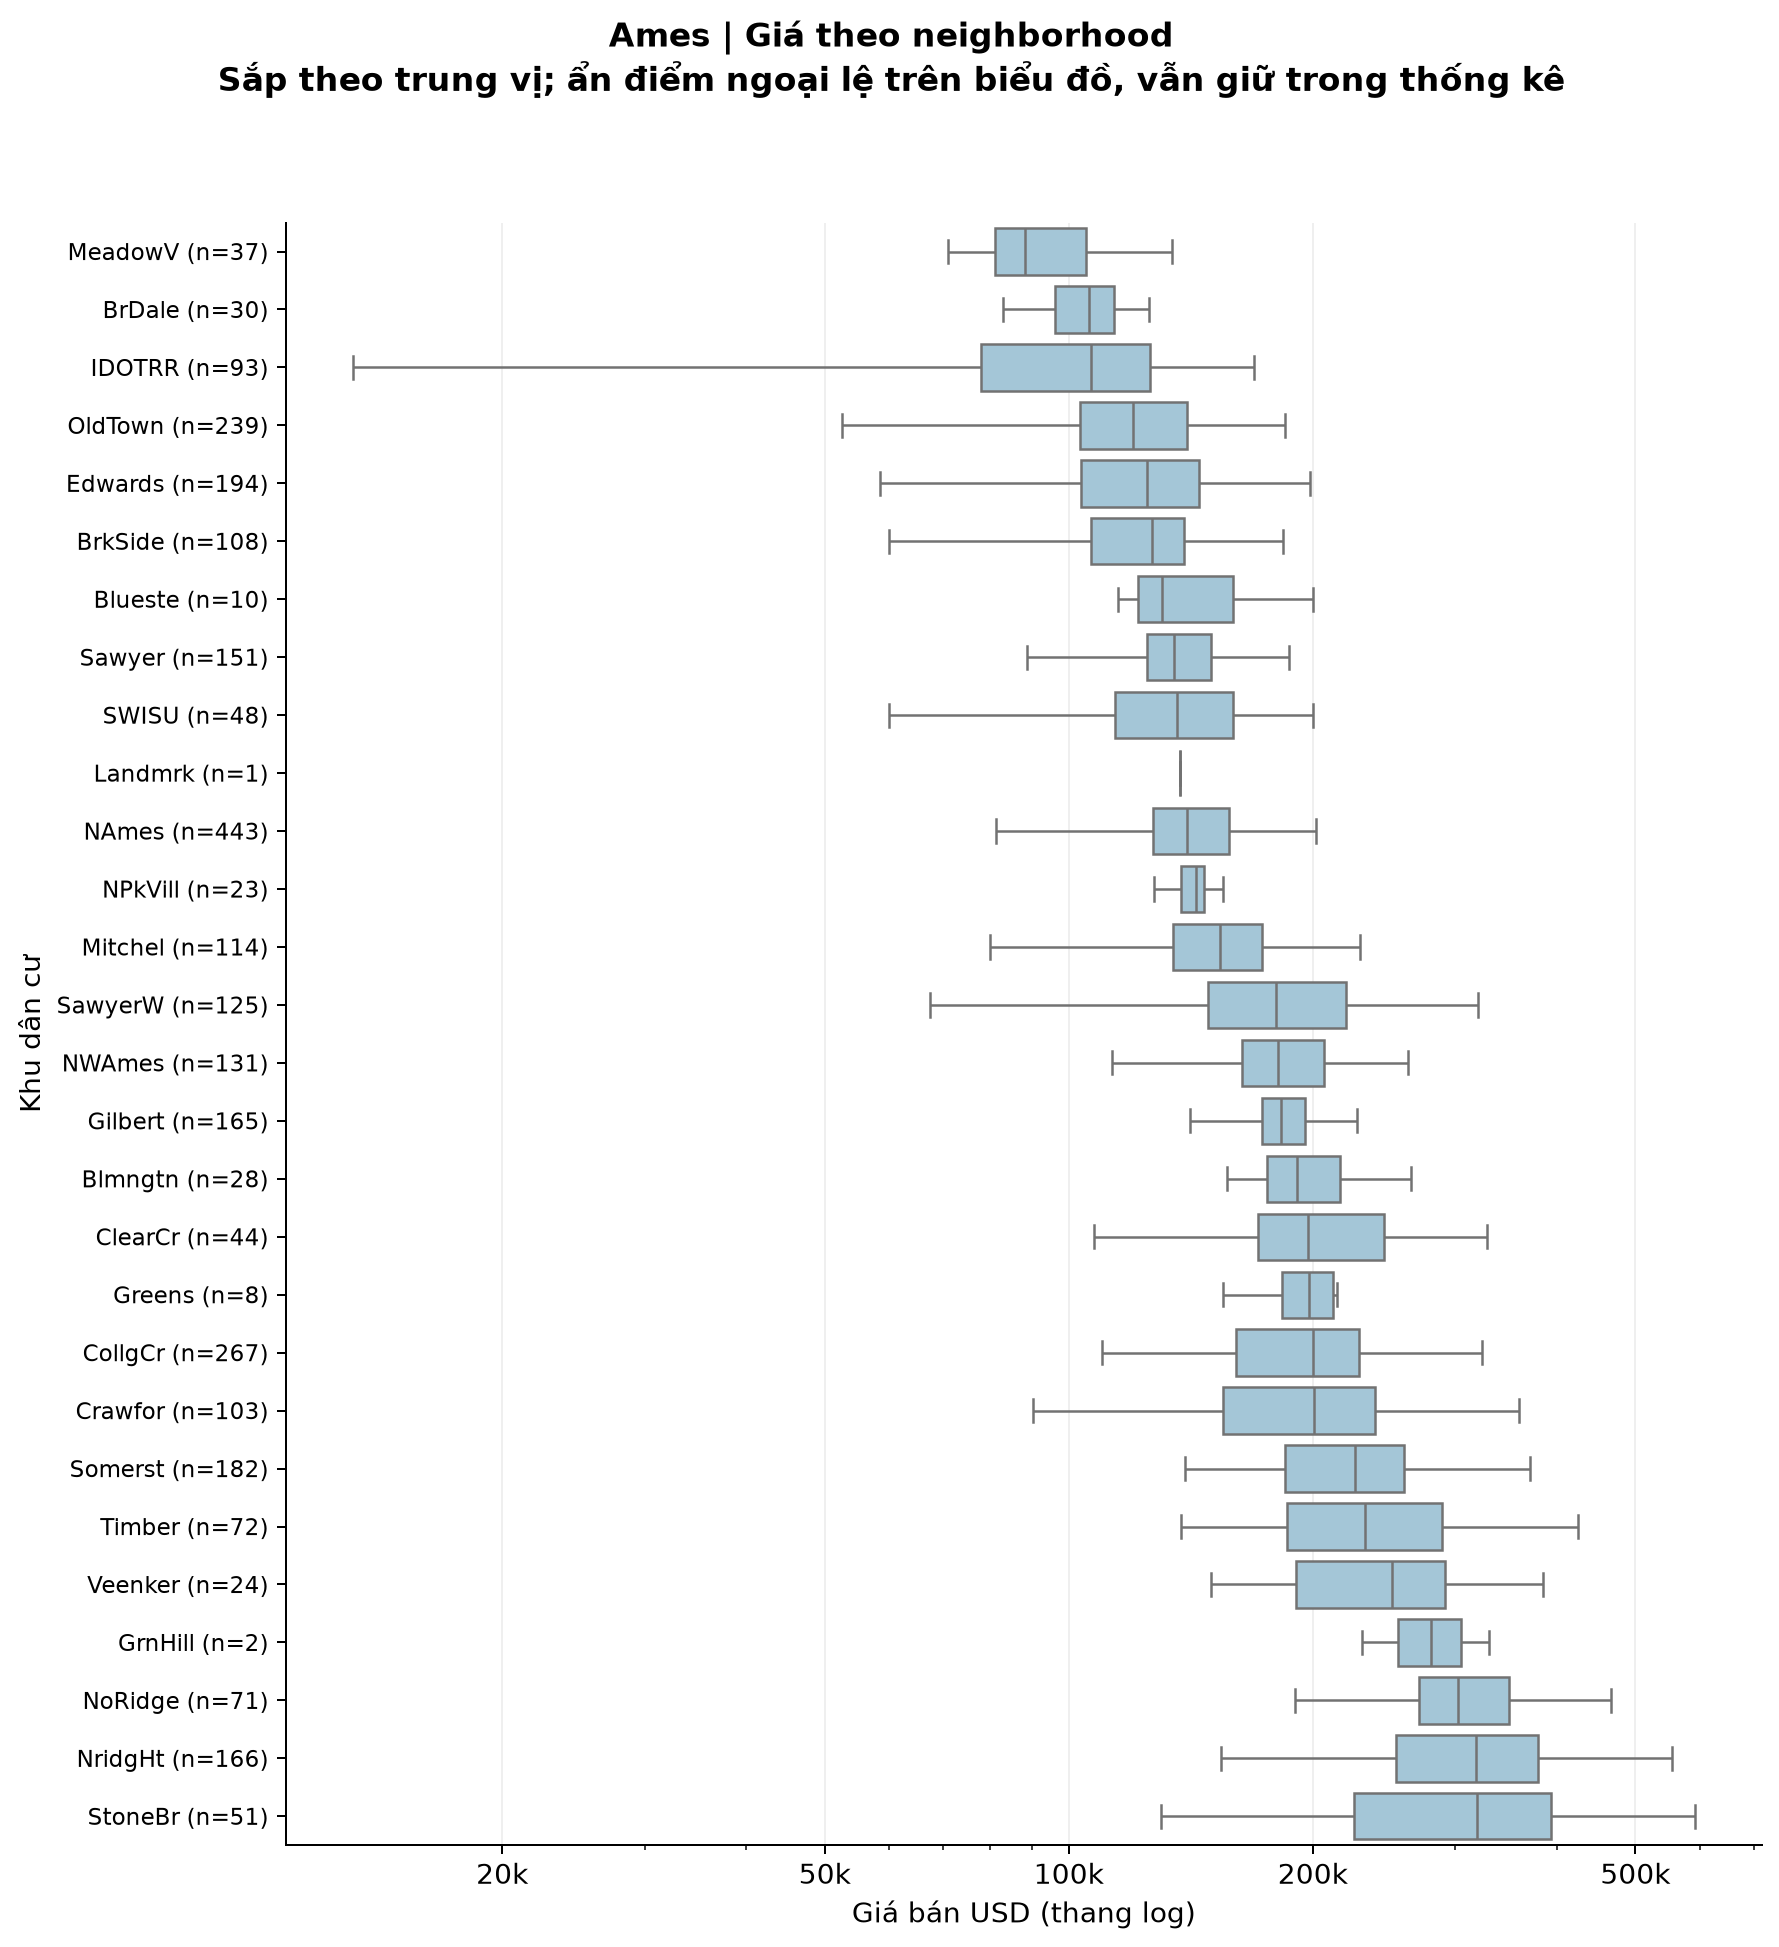

In [6]:
display(pd.read_csv(TABLES/"summary_statistics.csv"))
display(pd.read_csv(TABLES/"geographic_summary.csv"))
for key in ["king_county", "ames"]:
    for suffix in ["price_distribution", "geographic_boxplot"]:
        display(Image(filename=str(FIGURES/f"{key}_{suffix}.png")))


## So sánh nhóm bằng Welch t-test

Bảng kiểm định dưới đây dùng mẫu một giao dịch mỗi tài sản. Các trung bình trong bảng mô tả `group_summary.csv` dùng toàn giao dịch, vì vậy không thay thế trực tiếp cho trung bình suy luận. `p_holm` điều chỉnh đồng thời các thuộc tính trong từng bộ dữ liệu. Giá trị p bằng 0 trong CSV có nghĩa phép tính dấu phẩy động nhỏ hơn khả năng biểu diễn, không phải xác suất đúng bằng 0.

,variable,n_low,n_rest,mean_low,mean_rest,difference_low_minus_rest,ci95_low,ci95_high,t,df,p_raw,hedges_g,dataset,p_holm,significant_holm,sample,group_threshold
0,sqft_living,7062,14373,1532.880204,2352.886871,-820.006667,-839.636339,-800.376996,-81.879868,21285.243135,0.000000e+00,-0.982634,king_county,0.000000e+00,True,one_sale_per_property,360000.0
1,house_age,7062,14373,45.076182,42.307938,2.768244,1.984405,3.552083,6.922408,16657.092287,4.602238e-12,0.094294,king_county,4.602238e-12,True,one_sale_per_property,360000.0
2,sqft_lot,7062,14373,10715.882894,17307.866694,-6591.983800,-7562.487268,-5621.480332,-13.313485,21337.732326,2.798314e-40,-0.159126,king_county,5.596628e-40,True,one_sale_per_property,360000.0
3,grade,7062,14373,6.902294,8.034927,-1.132633,-1.158530,-1.106735,-85.725823,19901.615774,0.000000e+00,-1.082073,king_county,0.000000e+00,True,one_sale_per_property,360000.0
4,bathrooms,7062,14373,1.729574,2.307904,-0.578330,-0.597681,-0.558979,-58.580721,16394.890047,0.000000e+00,-0.802806,king_county,0.000000e+00,True,one_sale_per_property,360000.0
5,bedrooms,7062,14373,3.077315,3.514089,-0.436774,-0.461088,-0.412460,-35.211088,15373.545704,2.841588e-261,-0.494407,king_county,8.524765e-261,True,one_sale_per_property,360000.0
6,distance_to_center_km,7062,14373,23.526278,15.974760,7.551518,7.246842,7.856194,48.583471,11979.076056,0.000000e+00,0.751749,king_county,0.000000e+00,True,one_sale_per_property,360000.0
7,sqft_living,682,2248,1111.020528,1617.605427,-506.584899,-538.010176,-475.159622,-31.617098,1748.146961,6.715747e-174,-1.105794,ames,2.686299e-173,True,one_sale_per_property,128000.0
8,house_age,682,2248,63.602639,28.192171,35.410468,33.307949,37.512988,33.041070,1268.904415,2.958416e-173,1.344038,ames,8.875249e-173,True,one_sale_per_property,128000.0
9,lot_area,682,2248,7797.831378,10860.894128,-3063.062750,-3529.275070,-2596.850430,-12.883524,2452.093847,8.468148e-37,-0.393899,ames,1.693630e-36,True,one_sale_per_property,128000.0


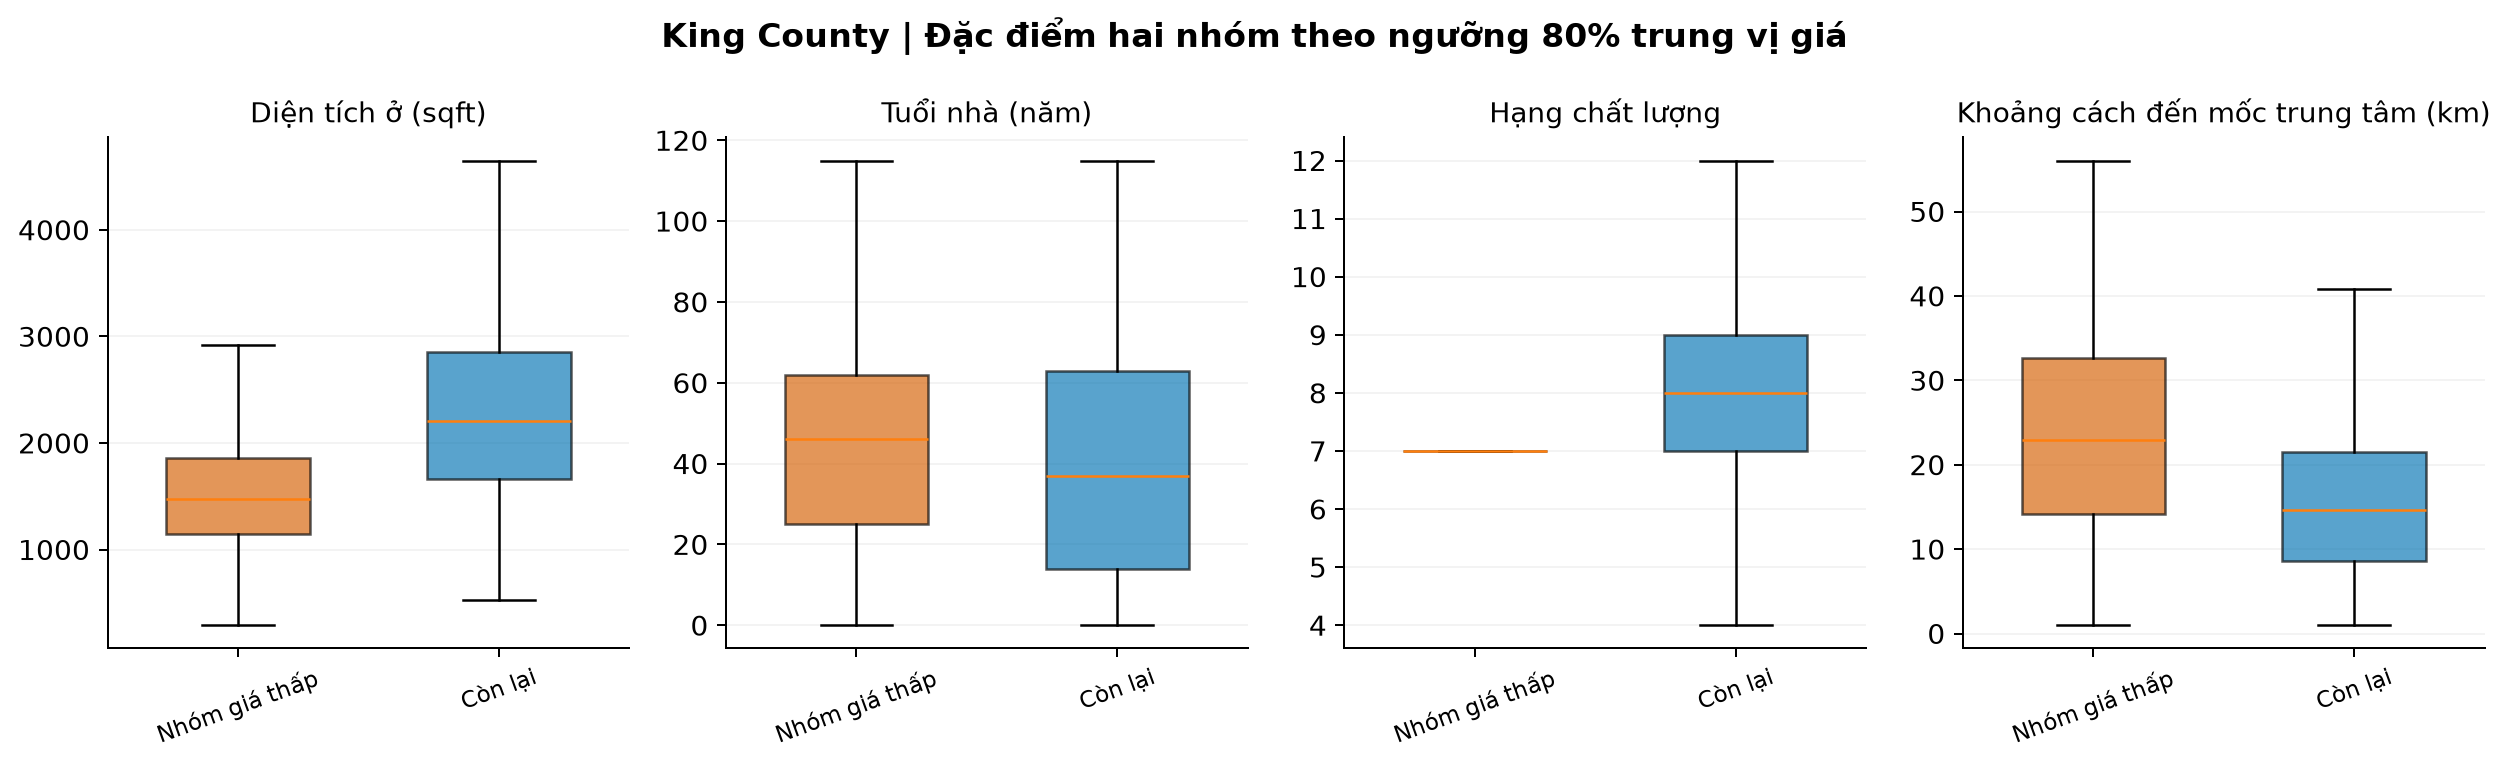

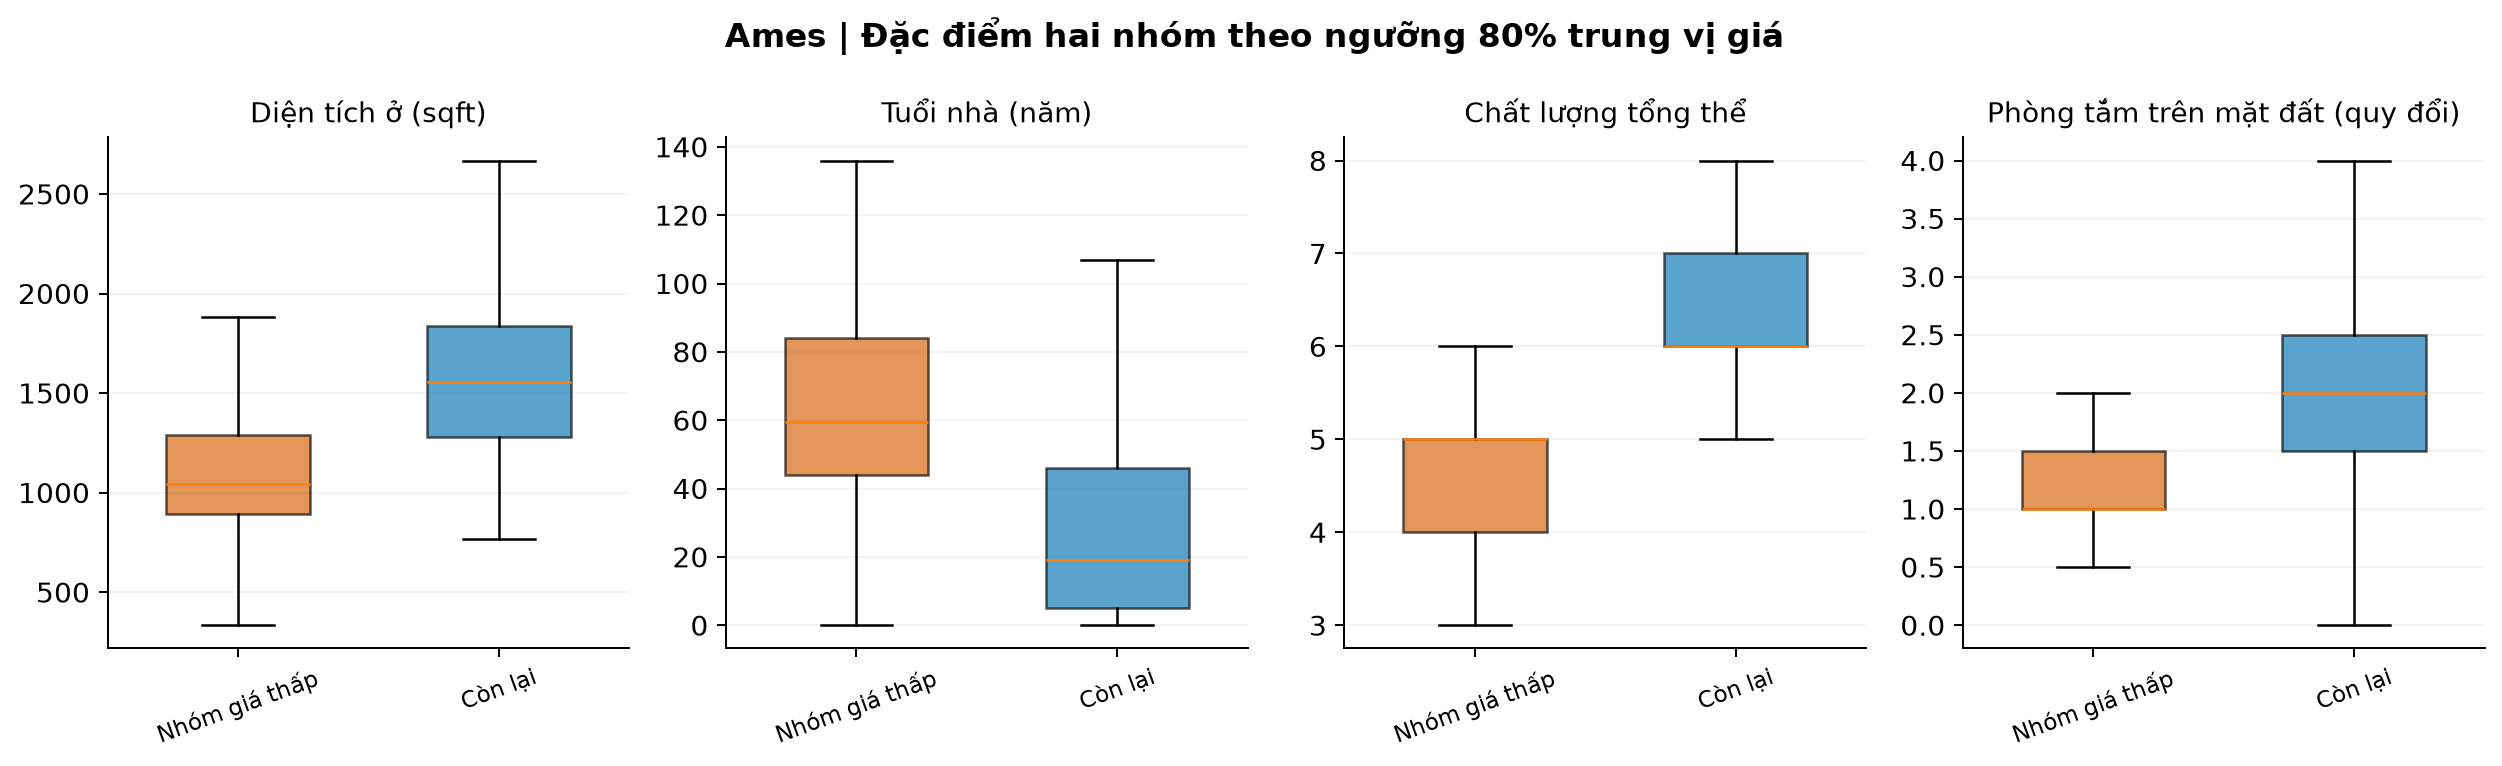

In [7]:
welch_results = pd.read_csv(TABLES/"welch_tests.csv")
display(welch_results)
for key in ["king_county", "ames"]:
    display(Image(filename=str(FIGURES/f"{key}_group_comparison.png")))


## Kiểm tra chiều quan hệ

Spearman dùng cặp quan sát không thiếu của từng biến. Hệ số rho phản ánh chiều và mức liên hệ đơn biến; vị trí, thời gian và chất lượng có thể gây nhiễu. Không dùng tương quan để kết luận một thuộc tính làm giá tăng hoặc giảm.

,dataset,variable,expected_direction,n,rho,p_one_sided,sample,p_holm,conclusion
0,king_county,sqft_living,positive,21435,0.644393,0.000000e+00,one_sale_per_property,0.000000e+00,supported
1,king_county,house_age,negative,21435,-0.101254,2.921799e-50,one_sale_per_property,2.921799e-50,supported
2,king_county,grade,positive,21435,0.658749,0.000000e+00,one_sale_per_property,0.000000e+00,supported
3,king_county,distance_to_center_km,negative,21435,-0.353050,0.000000e+00,one_sale_per_property,0.000000e+00,supported
4,ames,sqft_living,positive,2930,0.723342,0.000000e+00,one_sale_per_property,0.000000e+00,supported
5,ames,house_age,negative,2930,-0.678969,0.000000e+00,one_sale_per_property,0.000000e+00,supported
6,ames,overall_qual,positive,2930,0.808800,0.000000e+00,one_sale_per_property,0.000000e+00,supported


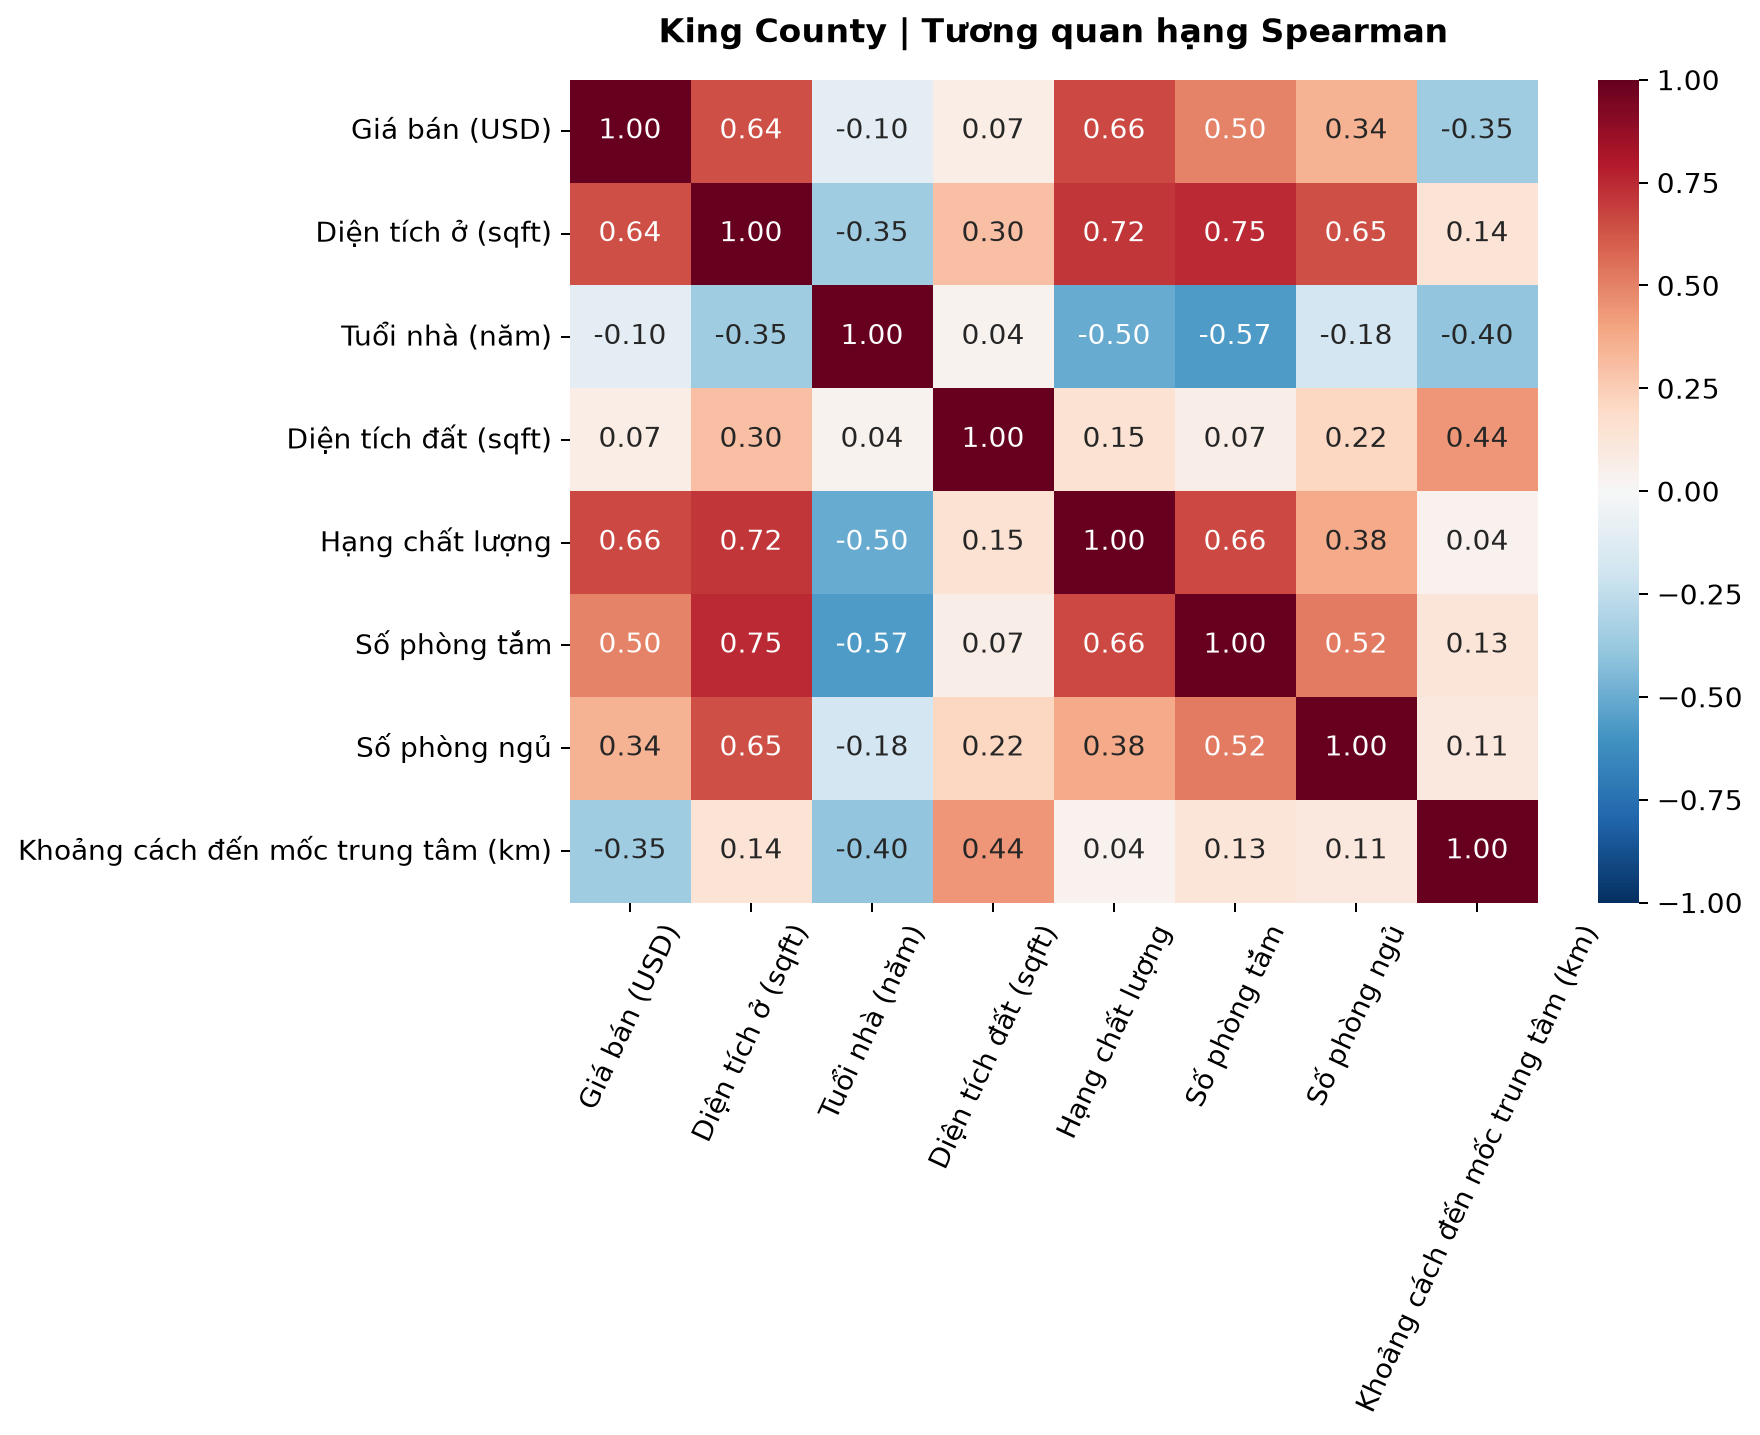

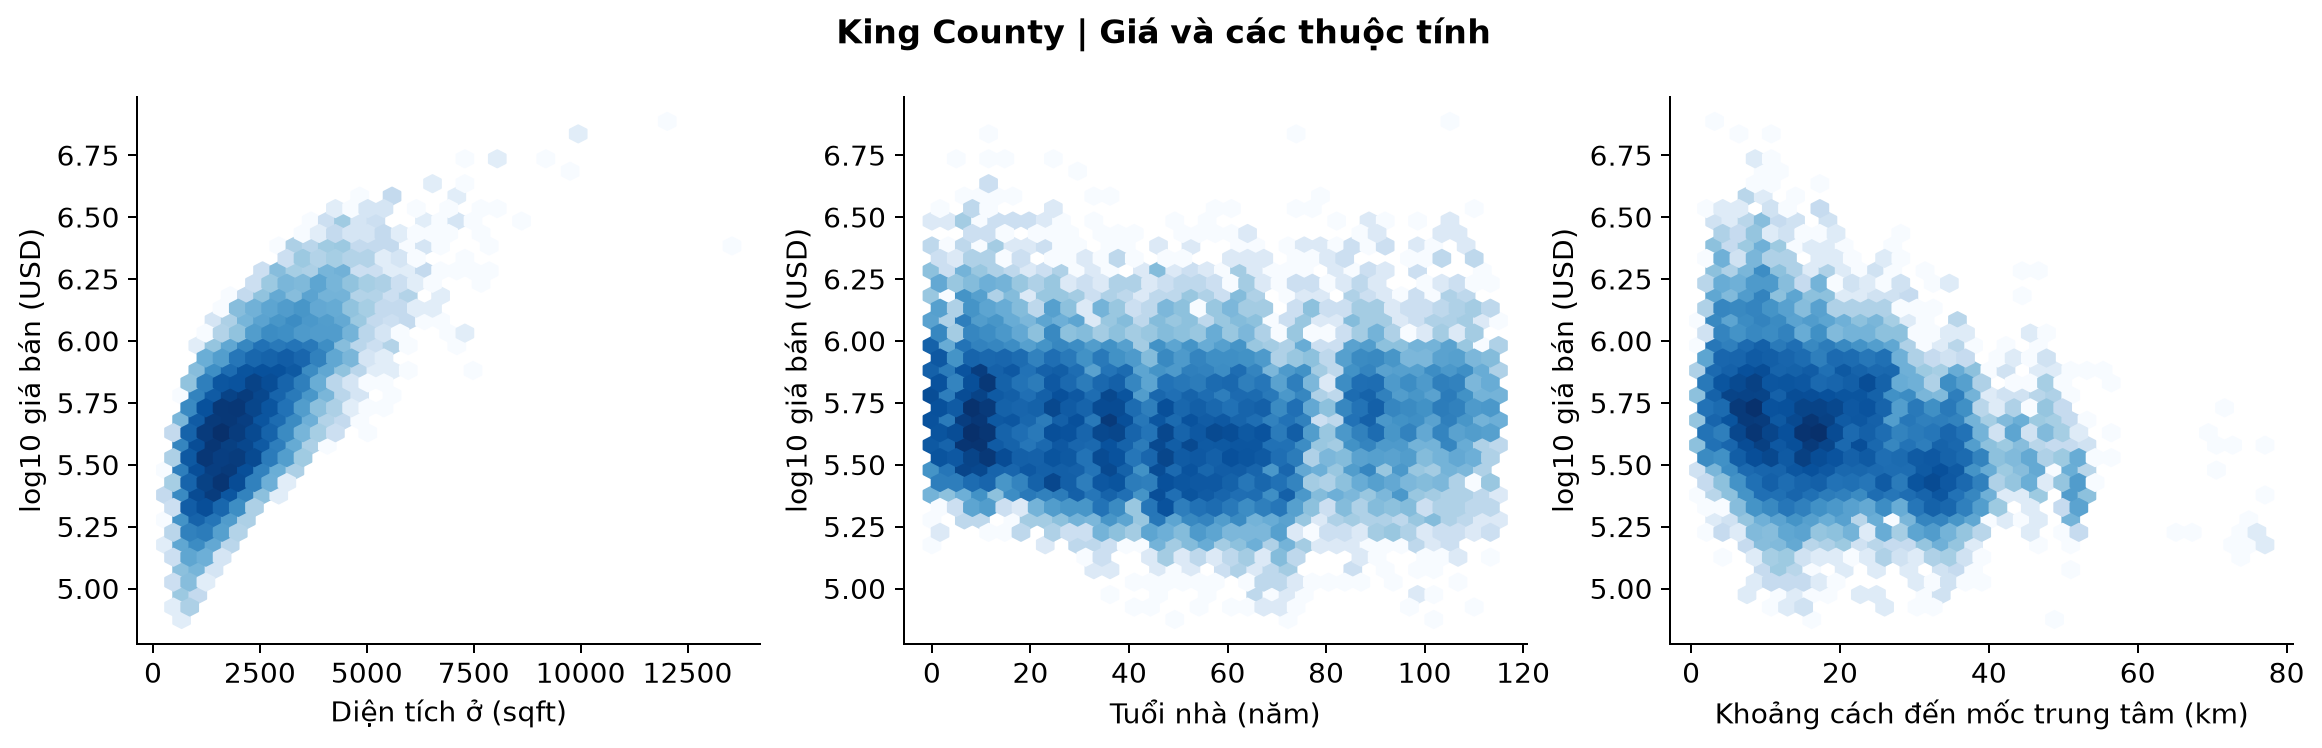

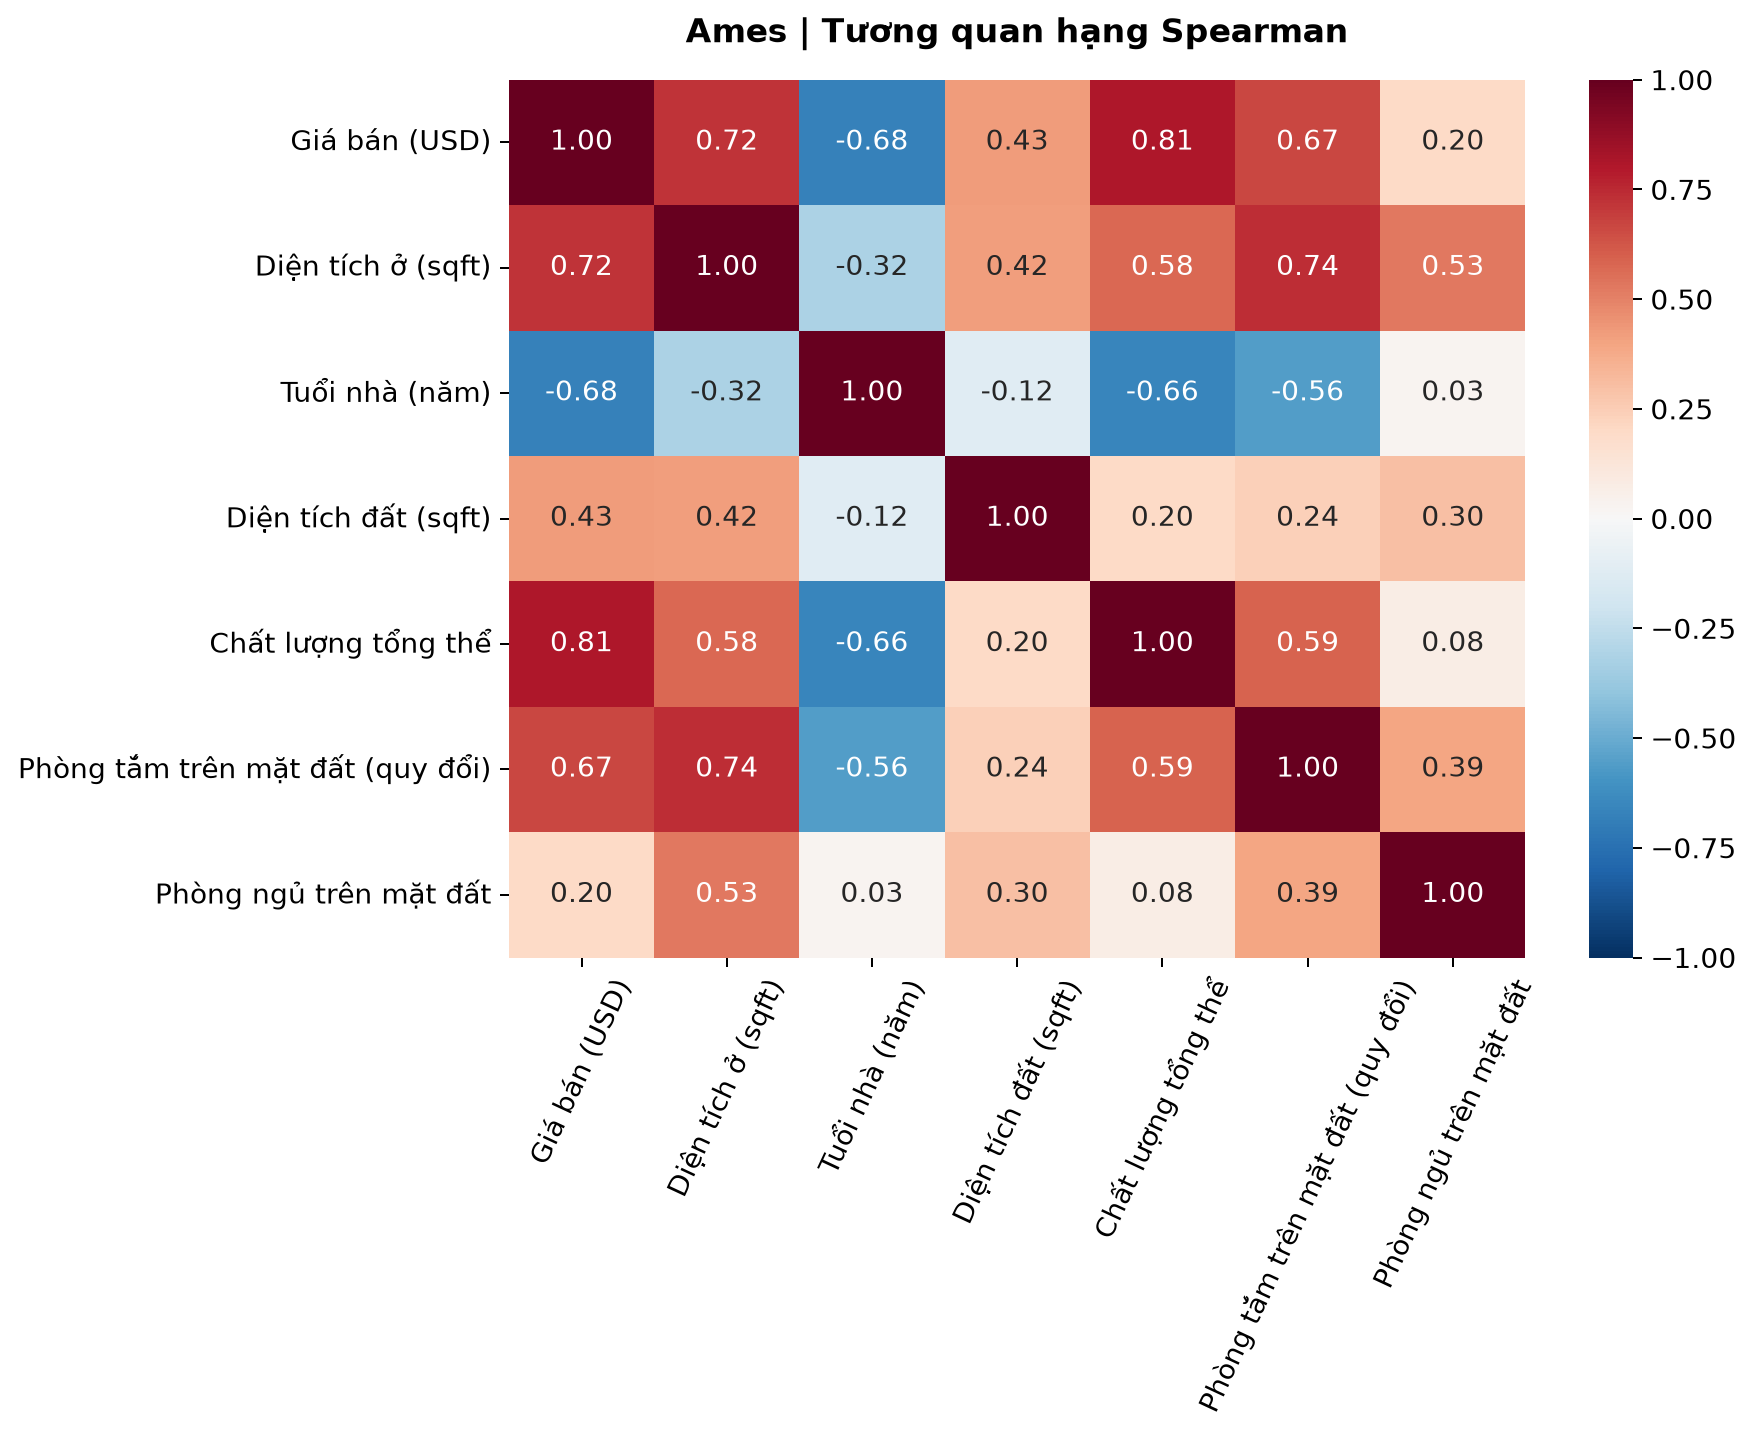

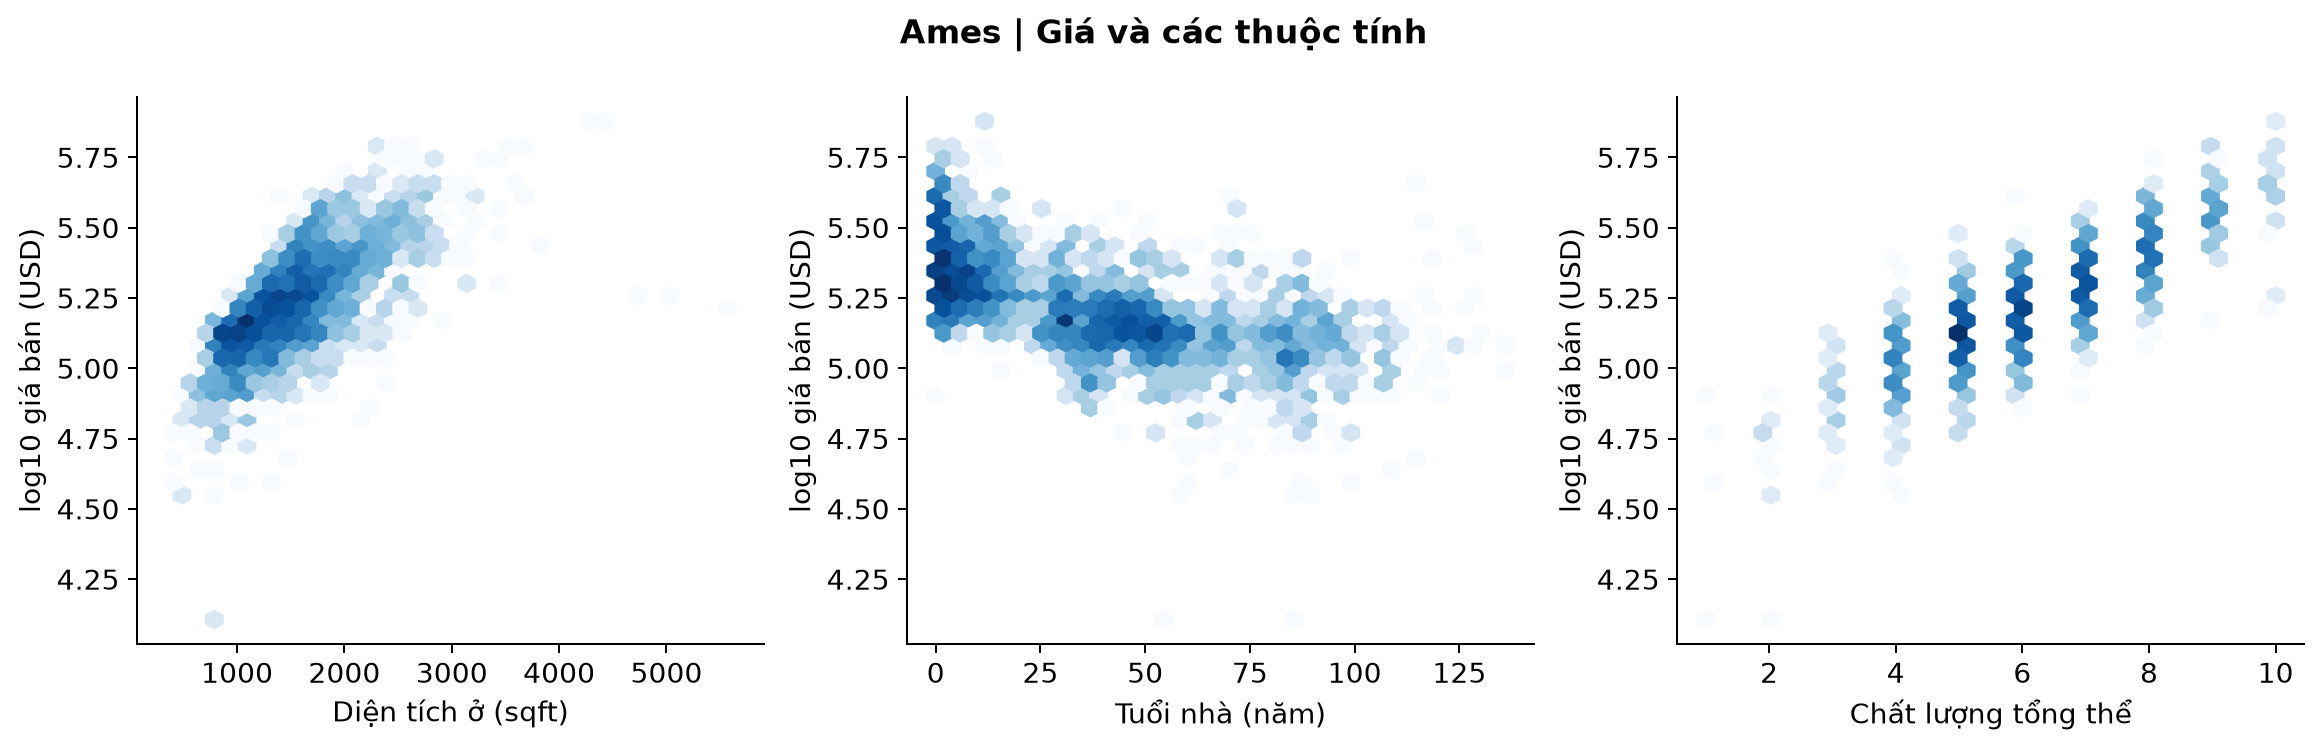

In [8]:
display(pd.read_csv(TABLES/"directional_tests.csv"))
for key in ["king_county", "ames"]:
    for suffix in ["spearman_heatmap", "price_relationships"]:
        display(Image(filename=str(FIGURES/f"{key}_{suffix}.png")))


## Kiểm tra độ nhạy và giới hạn

So sánh tỷ lệ nhãn theo trung vị toàn thị trường và trung vị địa phương để đánh giá ảnh hưởng vị trí. Welch được chạy lại trên toàn giao dịch, một giao dịch mỗi tài sản, sau bỏ các cờ IQR và sau bỏ quan sát có missing thực được nội suy (không loại NA cấu trúc). Riêng Ames thêm kịch bản bỏ diện tích ở trên 4.000 sqft theo cảnh báo của De Cock; đây là kiểm tra độ nhạy, không khẳng định mọi căn lớn đều sai.

Dữ liệu 2006–2010 của Ames và 2014–2015 của King County không phải thị trường hiện tại. Các kiểm định không thay thế mô hình giá có điều chỉnh đặc điểm; nhãn EDA không được dùng trực tiếp để quyết định mua nhà. Khi chuyển sang nhiệm vụ 4, cần tách train/test theo thời gian hoặc tài sản, fit imputer/ngưỡng trên train và loại biến phát sinh từ giá khỏi predictors.

In [9]:
sensitivity_results = pd.read_csv(TABLES/"sensitivity.csv")
display(sensitivity_results.loc[sensitivity_results.analysis.eq("threshold")])
display(sensitivity_results.loc[sensitivity_results.analysis.eq("welch_robustness")])
print((ROOT/"docs/eda_interpretation.txt").read_text(encoding="utf8"))


,dataset,analysis,discount,reference,n,n_low,share_low,overlap_with_global20,variable,difference_low_minus_rest,p_raw,p_holm,n_rest,hedges_g
0,king_county,threshold,0.1,global,21612,8931,0.413243,7130.0,NaN,NaN,NaN,NaN,NaN,NaN
1,king_county,threshold,0.1,zipcode,21612,7772,0.359615,4286.0,NaN,NaN,NaN,NaN,NaN,NaN
2,king_county,threshold,0.2,global,21612,7130,0.329909,7130.0,NaN,NaN,NaN,NaN,NaN,NaN
3,king_county,threshold,0.2,zipcode,21612,4834,0.223672,2964.0,NaN,NaN,NaN,NaN,NaN,NaN
4,king_county,threshold,0.3,global,21612,5054,0.233852,5054.0,NaN,NaN,NaN,NaN,NaN,NaN
5,king_county,threshold,0.3,zipcode,21612,2518,0.116509,1745.0,NaN,NaN,NaN,NaN,NaN,NaN
34,ames,threshold,0.1,global,2930,1099,0.375085,682.0,NaN,NaN,NaN,NaN,NaN,NaN
35,ames,threshold,0.1,neighborhood,2930,874,0.298294,434.0,NaN,NaN,NaN,NaN,NaN,NaN
36,ames,threshold,0.2,global,2930,682,0.232765,682.0,NaN,NaN,NaN,NaN,NaN,NaN
37,ames,threshold,0.2,neighborhood,2930,497,0.169625,258.0,NaN,NaN,NaN,NaN,NaN,NaN


,dataset,analysis,discount,reference,n,n_low,share_low,overlap_with_global20,variable,difference_low_minus_rest,p_raw,p_holm,n_rest,hedges_g
6,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,sqft_living,-818.891656,0.000000e+00,0.000000e+00,14482.0,-0.982001
7,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,house_age,2.760886,4.123526e-12,4.123526e-12,14482.0,0.094074
8,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,sqft_lot,-6573.701308,1.257514e-40,2.515027e-40,14482.0,-0.159137
9,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,grade,-1.132066,0.000000e+00,0.000000e+00,14482.0,-1.080097
10,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,bathrooms,-0.577488,0.000000e+00,0.000000e+00,14482.0,-0.801213
11,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,bedrooms,-0.437094,2.228056e-263,6.684167e-263,14482.0,-0.494189
12,king_county,welch_robustness,NaN,all_transactions,21612,7130,NaN,NaN,distance_to_center_km,7.549112,0.000000e+00,0.000000e+00,14482.0,0.752422
13,king_county,welch_robustness,NaN,one_sale_per_property,21435,7062,NaN,NaN,sqft_living,-820.006667,0.000000e+00,0.000000e+00,14373.0,-0.982634
14,king_county,welch_robustness,NaN,one_sale_per_property,21435,7062,NaN,NaN,house_age,2.768244,4.602238e-12,4.602238e-12,14373.0,0.094294
15,king_county,welch_robustness,NaN,one_sale_per_property,21435,7062,NaN,NaN,sqft_lot,-6591.983800,2.798314e-40,5.596628e-40,14373.0,-0.159126


NHIỆM VỤ 3  PHÂN TÍCH MÔ TẢ VÀ CHẨN ĐOÁN

price < 0.8 * median(price) trong từng bộ dữ liệu sạch; strict <
Nhãn low-price proxy, không chứng minh nhà bị định giá thấp so với giá trị thị trường.
King County dùng giao dịch sớm nhất mỗi id; Ames mỗi PID một quan sát. Ngưỡng nhóm giữ theo toàn bộ dữ liệu sạch.
Holm điều chỉnh riêng từng dataset và từng họ Welch hoặc Spearman; CI95% Welch riêng từng biến, không đồng thời.

King County: n=21,612; suy luận n=21,435; trung vị 450,000 USD; ngưỡng 360,000 USD; nhóm thấp 7,130 (32.99%); nhóm thấp theo địa phương 4,834 (22.37%).
Welch sqft_living: mean thấp=1532.880; còn lại=2352.887; chênh lệch=-820.007; CI95% [-839.636,-800.377]; p Holm=0; Hedges g=-0.983.
Welch house_age: mean thấp=45.076; còn lại=42.308; chênh lệch=2.768; CI95% [1.984,3.552]; p Holm=4.602e-12; Hedges g=0.094.
Welch sqft_lot: mean thấp=10715.883; còn lại=17307.867; chênh lệch=-6591.984; CI95% [-7562.487,-5621.480]; p Holm=5.597e-40; Hedges g=-0.159.
Welch grade: mean thấp=6.902

## Nguồn và minh bạch sử dụng AI

Nguồn dữ liệu, bản raw và checksum: `metadata/sources.json` (hoặc manifest nguồn trong thư mục `metadata`). King County có nguồn gốc bộ House Sales in King County của Harlfoxem trên Kaggle. Ames do Dean De Cock công bố, dựa trên Ames Assessor's Office; xem [bài báo gốc](https://jse.amstat.org/v19n3/decock.pdf) và [từ điển gốc](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt).

AI hỗ trợ soạn mã ETL, EDA, kiểm định, diễn giải và cấu trúc báo cáo. Dữ liệu không do AI tạo. Toàn bộ số liệu, bảng và biểu đồ do mã chạy trên CSV đã lưu; audit và raw cho phép kiểm tra lại. Các ngưỡng và mốc trung tâm là lựa chọn phân tích của nhóm và được công khai. Notebook có assertions kiểm tra miền giá trị, CI và hiệu chỉnh Holm.